<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-12/lab-073-qubo-qaoa.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 073. QUBO and the quantum approximate optimisation algorithm

Many decisions are choices between two options made for many items at once. A delivery is assigned to one of two vans, a component to one of two chips, a vertex of a network to one of two groups. When the cost of a choice depends on pairs of items, the task is a quadratic unconstrained binary optimisation problem (QUBO). Its candidate solutions are bit strings, so a register of qubits measured in the computational basis produces candidate solutions directly. A quantum algorithm for such a problem prepares a state whose measurements return good bit strings with high probability, and the answer is the best bit string among the measured ones.

We take as the main example one QUBO problem, the maximum cut of a graph with $N=8$ vertices. We first write the problem as a cost function of bit strings and solve it exactly by checking all $2^8=256$ candidates. We then turn the cost into an Ising Hamiltonian that is diagonal in the computational basis, so that every basis state is a candidate with its cost as the energy. The quantum approximate optimisation algorithm (QAOA) prepares a state with a circuit that alternates evolution under this Hamiltonian with a mixing evolution, and its angles are trained in a state-vector simulation with automatic differentiation. We measure the trained state and compare the sampled bit strings with random guessing. The same algorithm is then applied to two further problems with eight binary variables, number partitioning and the maximum independent set.

Section 2 sets up the simulator, Sections 3 and 4 define the QUBO, the graph and the exact solution, Section 5 builds the Ising Hamiltonian, and Section 6 explains how a measured bit string becomes an answer. Sections 7 to 9 define the QAOA circuit and train it at depths one to four, Section 10 samples the trained circuits, and Section 11 applies the algorithm to number partitioning. These sections form the core route. Section 12 treats the maximum independent set, whose constraint enters the cost as a penalty, Section 13 lists further problems in QUBO form, and Section 14 relates the QAOA to adiabatic evolution. These three sections can be read at home, and their cells run with the rest.

All results are exact state-vector calculations or simulated measurement records with fixed random seeds.

## 1. Double-precision arithmetic

We work in double precision, `float64` and `complex128`. JAX does the linear algebra, the automatic differentiation and the random sampling on the CPU, NumPy handles the enumeration of bit strings, and Matplotlib draws the figures. The cells run in order.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"          # small calculations, the CPU is enough
import json, time, math
from pathlib import Path
from functools import partial
import numpy as np
import jax
import jax.numpy as jnp
from jax import lax
from jax.scipy.linalg import expm
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)
CDTYPE = jnp.complex128
TOL = 1e-12
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
                     "legend.fontsize": 10, "figure.figsize": (4.8, 3.2), "savefig.bbox": "tight",
                     "pdf.fonttype": 42, "ps.fonttype": 42})
COL = {"g0": "#A9CDEB", "g1": "#F0B48C", "cut": "#D35A05", "edge": "#9AA0A6", "qaoa": "#D35A05", "rand": "#9AA0A6", "opt": "#002B5C"}
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150)
started = time.perf_counter()
NUMBERS = {}
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. State-vector simulator

The simulator stores the state of $N$ qubits as a tensor $\psi[b_0,\dots,b_{N-1}]$ with one axis per qubit, and qubit 0 is the most significant bit, so the amplitude of the bit string $b_0b_1\dots b_{N-1}$ sits at the flat index
$$k=\sum_{i=0}^{N-1}b_i\,2^{N-1-i}. \tag{1}$$
A rotation generated by a Pauli matrix $\hat P$ is
$$\hat R_P(\theta)=e^{-i\theta\hat P/2}=\cos\frac\theta2\,\hat I-i\sin\frac\theta2\,\hat P , \tag{2}$$
and a one-qubit gate acts on qubit $i$ by a contraction with axis $i$ of the state tensor. The two-qubit rotation $\hat R_{zz}(\theta)=e^{-i\theta\hat Z_i\hat Z_j/2}$ is diagonal in the computational basis. Since $\hat Z_i\hat Z_j|\mathbf b\rangle=(-1)^{b_i+b_j}|\mathbf b\rangle$, it multiplies the amplitude of each bit string by the phase $e^{-i\theta(-1)^{b_i+b_j}/2}$. The checks compare the contraction with the Kronecker-product matrix and the phase form of $\hat R_{zz}$ with the matrix exponential.

In [2]:
# recap: one-qubit matrices, rotations (2), gates on a state tensor, diagonal R_zz as a phase vector
I2 = jnp.eye(2, dtype=CDTYPE)
X = jnp.array([[0, 1], [1, 0]], dtype=CDTYPE)
Z = jnp.array([[1, 0], [0, -1]], dtype=CDTYPE)

def rot(P, theta):
    return jnp.cos(theta / 2) * I2 - 1j * jnp.sin(theta / 2) * P

def apply_1q(psi, U, q):
    return jnp.moveaxis(jnp.tensordot(U, psi, axes=([1], [q])), 0, q)

def bit_table(n):
    k = np.arange(2 ** n)
    return (k[:, None] >> (n - 1 - np.arange(n))) & 1          # row k = bits of index k, equation (1)

def zz_signs(n, i, j):
    b = bit_table(n)
    return (-1.0) ** (b[:, i] + b[:, j])                        # eigenvalue of Z_i Z_j on every bit string

psi3 = jax.random.normal(jax.random.PRNGKey(7301), (8,)) + 0j; psi3 /= jnp.linalg.norm(psi3)
U_test = rot(X, 0.9)
assert jnp.allclose(apply_1q(psi3.reshape(2, 2, 2), U_test, 2).reshape(-1), jnp.kron(jnp.kron(I2, I2), U_test) @ psi3, atol=TOL)
ZIZ = jnp.kron(jnp.kron(Z, I2), Z)
assert jnp.allclose(expm(-1j * 0.7 / 2 * ZIZ) @ psi3, jnp.exp(-1j * 0.7 / 2 * zz_signs(3, 0, 2)) * psi3, atol=1e-12)
print("simulator ready: contraction = Kronecker matrix, R_zz = phase vector")

simulator ready: contraction = Kronecker matrix, R_zz = phase vector


## 3. Quadratic unconstrained binary optimisation

A QUBO problem has $N$ binary variables $x_i\in\{0,1\}$, collected in the vector $\mathbf x=(x_0,\dots,x_{N-1})$, and a real symmetric $N\times N$ matrix $Q$. Each variable will be stored in one qubit, so $N$ is also the number of qubits, and in a graph problem the number of vertices. The problem asks for the vector that minimises the quadratic cost
$$C(\mathbf x)=\mathbf x^{T}Q\,\mathbf x=\sum_{i,j}Q_{ij}\,x_ix_j . \tag{3}$$
A binary variable satisfies $x_i^2=x_i$, so the diagonal elements $Q_{ii}$ act as linear costs, and every quadratic function of binary variables has the form (3) up to a constant. The word unconstrained means that all $2^N$ vectors are allowed. Constraints, such as a fixed number of ones, are added to the cost as penalty terms.

The sketch evaluates the cost (3) for one bit string, where only the entries of $Q$ in rows and columns with $x_i=1$ contribute.

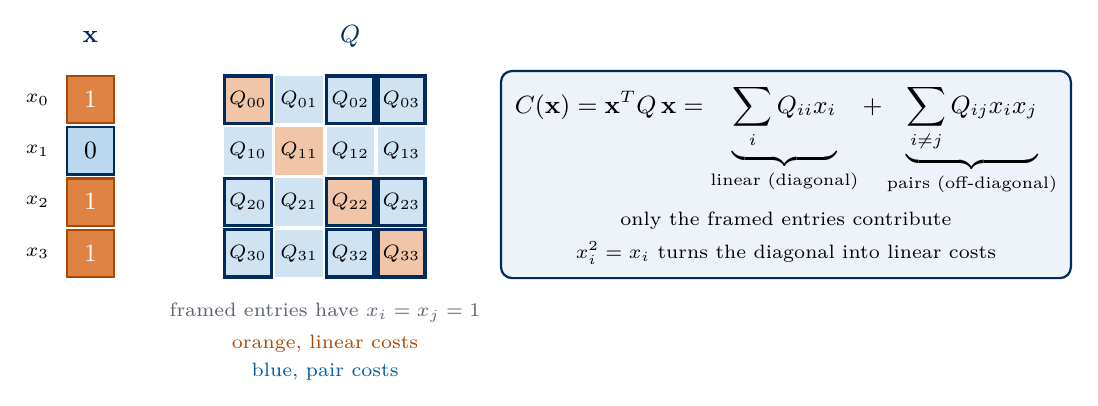

Checking every vector costs $2^N$ evaluations of $C$, about $10^{15}$ for $N=50$. QUBO is NP-hard, so no known algorithm solves every instance in a time that grows only polynomially with $N$, and practical solvers for large instances are heuristics. A greedy method flips one variable at a time as long as the cost decreases. Simulated annealing also accepts some cost increases, with a probability that decreases during the run, in order to leave local minima. For the instance studied here, $2^8=256$ candidates are checked in a fraction of a second, which gives the exact answer against which the quantum algorithm is compared.

## 4. MaxCut

A graph consists of $N$ vertices and a set $E$ of edges, each joining a pair of vertices $(i,j)$. As an analogy, the vertices can be people and the edges conflicts between them, and the task is to split the people into two rooms so that as many conflicting pairs as possible end up in different rooms. A split of the vertices into two groups is called a *cut*, because drawing a line between the groups cuts every edge that crosses it. We label the groups by a binary variable per vertex, $x_i=0$ for the first group and $x_i=1$ for the second, so a cut is a bit string $\mathbf x=x_0x_1\dots x_{N-1}$. The *size* of the cut is the number of edges whose two ends carry different labels, and the maximum-cut problem (MaxCut) asks for the bit string with the largest cut size.

On a square, four vertices $0,1,2,3$ are joined in a ring by the edges $(0,1)$, $(1,2)$, $(2,3)$ and $(3,0)$. The bit string $0000$ puts everyone in one group and cuts no edge. The string $1000$ moves vertex $0$ to the other group and cuts its two edges $(0,1)$ and $(3,0)$, so its cut size is two. The string $1010$ alternates the groups around the ring, so every edge joins vertices of different groups and all four edges are cut. No string can do better, so the maximum cut of the square is four, reached by $1010$ and by its complement $0101$. Exchanging the two groups never changes a cut, so the optimal bit strings always come in such complementary pairs. A triangle behaves differently, because around a cycle of three vertices the labels cannot alternate, and at most two of its three edges can be cut. Odd cycles in a graph make some edges impossible to cut.

The sketch shows the optimal cut $1010$ of the square, which cuts all four edges, and the triangle, where one edge always stays uncut.

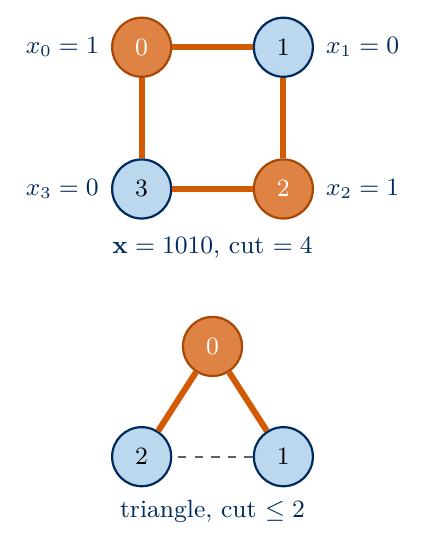

For a square the answer is evident, but in general the only sure method is to compare candidates, and their number $2^N$ doubles with every vertex. MaxCut is one of the problems that Karp proved NP-complete in its decision form [4], so no algorithm is known that finds the optimum of every graph in a time that grows polynomially with $N$. Approximate algorithms are therefore judged by the approximation ratio, the cut they find divided by the maximum cut. The best known polynomial-time classical algorithm, based on semidefinite programming, guarantees a ratio of at least $0.878$ on every graph [5]. MaxCut appears in the partitioning of networks and circuits, in clustering, where the edges carry the dissimilarities of items, and in physics as the ground-state problem of an Ising antiferromagnet, where a cut edge is a satisfied bond.

An edge $(i,j)$ is cut when exactly one of $x_i$, $x_j$ equals one, and the expression $x_i+x_j-2x_ix_j$ equals one in that case and zero otherwise. The cut size is therefore
$$\mathrm{cut}(\mathbf x)=\sum_{(i,j)\in E}\big(x_i+x_j-2x_ix_j\big). \tag{4}$$
Maximising the cut is minimising $C(\mathbf x)=-\mathrm{cut}(\mathbf x)$, a QUBO with the matrix
$$Q_{ii}=-d_i,\qquad Q_{ij}=Q_{ji}=\begin{cases}1 & (i,j)\in E\\ 0 & \text{otherwise}\end{cases}\quad(i\neq j), \tag{5}$$
where the degree $d_i$ is the number of edges at vertex $i$. Each edge contributes $Q_{ij}+Q_{ji}=2$ to the product term $2x_ix_j$ of equation (4), and the linear terms $x_i$ collect on the diagonal.

Our graph has $N=8$ vertices and twelve edges. It is a ring of eight vertices in which each vertex is also joined to the opposite vertex, so every vertex has three neighbours. It contains cycles of odd length, such as $0$–$1$–$2$–$3$–$4$–$0$, and on a cycle of odd length at least one edge stays uncut, so no division cuts all edges. The code builds $Q$, checks equation (5) against the direct count of cut edges for all 256 bit strings, and finds the maximum cut by exhaustive search. The bit string $\mathbf b=b_0\dots b_7$ of a candidate is $\mathbf x$ itself, $b_i=x_i$.

In [3]:
n = 8
EDGES = [(0, 1), (0, 4), (0, 7), (1, 2), (1, 5), (2, 3), (2, 6), (3, 4), (3, 7), (4, 5), (5, 6), (6, 7)]
Q = np.zeros((n, n))
for i, j in EDGES:
    Q[i, j] += 1; Q[j, i] += 1; Q[i, i] -= 1; Q[j, j] -= 1          # equation (5)
BITS = bit_table(n)                                                   # all 256 candidate bit strings x = b
cost = np.einsum("ki,ij,kj->k", BITS, Q, BITS)                        # C(x) = x^T Q x for every candidate
cut = np.array([sum(int(b[i] != b[j]) for i, j in EDGES) for b in BITS])
assert np.array_equal(cost, -cut)
assert np.all(np.diag(Q) == -3)

cut_max = int(cut.max())
opt_idx = np.flatnonzero(cut == cut_max)
fmt = lambda k: "".join(map(str, BITS[k]))
print("QUBO matrix Q:\n", Q.astype(int))
print(f"maximum cut = {cut_max} of {len(EDGES)} edges, reached by {len(opt_idx)} bit strings:", [fmt(k) for k in opt_idx])
print("number of bit strings with cut size 0, 1, ..., 12:", np.bincount(cut, minlength=len(EDGES) + 1))
print(f"mean cut of a uniformly random bit string = {cut.mean():.2f} = |E|/2")
for nn in (8, 20, 50, 100):
    print(f"n = {nn:3d}: 2^n = {2.0 ** nn:.2e} candidates")
NUMBERS["NumVertices"] = str(n)
NUMBERS["NumEdges"] = str(len(EDGES))
NUMBERS["MaxCut"] = str(cut_max)
NUMBERS["NumOptimal"] = str(len(opt_idx))
NUMBERS["RandomMeanCut"] = f"{cut.mean():.1f}"

QUBO matrix Q:
 [[-3  1  0  0  1  0  0  1]
 [ 1 -3  1  0  0  1  0  0]
 [ 0  1 -3  1  0  0  1  0]
 [ 0  0  1 -3  1  0  0  1]
 [ 1  0  0  1 -3  1  0  0]
 [ 0  1  0  0  1 -3  1  0]
 [ 0  0  1  0  0  1 -3  1]
 [ 1  0  0  1  0  0  1 -3]]
maximum cut = 10 of 12 edges, reached by 8 bit strings: ['00101101', '01001011', '01011010', '01101001', '10010110', '10100101', '10110100', '11010010']
number of bit strings with cut size 0, 1, ..., 12: [ 2  0  0 16 28 48 72 48 18 16  8  0  0]
mean cut of a uniformly random bit string = 6.00 = |E|/2
n =   8: 2^n = 2.56e+02 candidates
n =  20: 2^n = 1.05e+06 candidates
n =  50: 2^n = 1.13e+15 candidates
n = 100: 2^n = 1.27e+30 candidates


The maximum cut contains 10 of the 12 edges, and eight bit strings reach it. They come in pairs related by flipping every bit, because exchanging the two groups leaves every cut unchanged. A uniformly random bit string cuts each edge with probability one half and therefore six edges on average. The figure shows the graph divided by one of the optimal bit strings, with the cut edges drawn in colour, and the number of bit strings for each cut size.

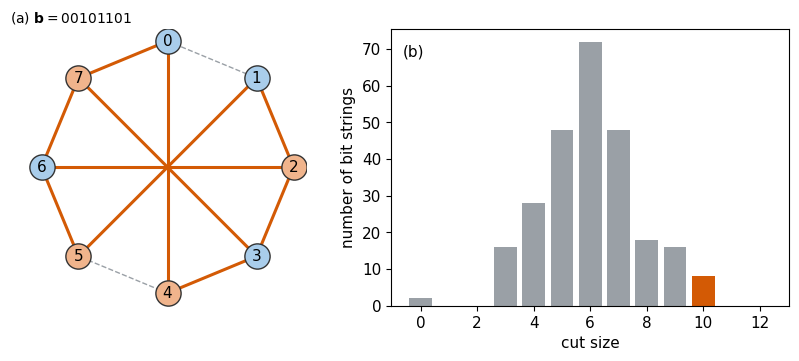

In [4]:
angles = np.pi / 2 - 2 * np.pi * np.arange(n) / n
POS = np.c_[np.cos(angles), np.sin(angles)]

def draw_graph(ax, bits):
    for i, j in EDGES:
        is_cut = bits[i] != bits[j]
        ax.plot(*POS[[i, j]].T, color=COL["cut"] if is_cut else COL["edge"], lw=2.2 if is_cut else 1.0,
                ls="-" if is_cut else "--", zorder=1)
    for i in range(n):
        ax.scatter(*POS[i], s=330, color=COL["g1"] if bits[i] else COL["g0"], edgecolor="0.2", zorder=2)
        ax.text(*POS[i], str(i), ha="center", va="center", fontsize=11, zorder=3)
    ax.set_aspect("equal"); ax.axis("off")

fig, axs = plt.subplots(1, 2, figsize=(10.0, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
draw_graph(axs[0], BITS[opt_idx[0]])
axs[0].text(-1.25, 1.15, f"(a) $\\mathbf{{b}}={fmt(opt_idx[0])}$", fontsize=10)
counts = np.bincount(cut, minlength=len(EDGES) + 1)
axs[1].bar(np.arange(len(counts)), counts, color=COL["rand"])
axs[1].bar([cut_max], [counts[cut_max]], color=COL["cut"])
axs[1].set_xlabel("cut size"); axs[1].set_ylabel("number of bit strings"); axs[1].set_xticks(range(0, 13, 2))
axs[1].text(0.03, 0.9, "(b)", transform=axs[1].transAxes)
save(fig, "fig_lab073_graph"); plt.show()

Panel (a) shows the graph with the vertices coloured by the optimal bit string $00101101$, blue for $b_i=0$ and orange for $b_i=1$. The ten cut edges are solid and the two uncut edges are dashed. Panel (b) counts the 256 bit strings by their cut size, with the eight optimal strings in orange. Most bit strings cut five to seven edges, and the optimum lies in the tail of the distribution, which a random guess reaches with probability $8/256=1/32$.

## 5. The Ising Hamiltonian of a QUBO

A qubit measured in the computational basis gives the bit $b_i$, and its Pauli operator $\hat Z_i$ has the eigenvalue $z_i=1-2b_i=\pm1$. We identify each binary variable with the bit of one qubit, $x_i=b_i$, so that
$$x_i=\frac{1-z_i}2 . \tag{6}$$
Inserting equation (6) into the cost (3) and using $z_i^2=1$ for the diagonal terms gives
$$C=\frac14\sum_{i,j}Q_{ij}(1-z_i)(1-z_j)=\underbrace{\frac14\sum_{i,j}Q_{ij}+\frac14\sum_iQ_{ii}}_{\text{constant }c_0}\;\underbrace{-\;\frac14\sum_i\Big[\sum_j(Q_{ij}+Q_{ji})\Big]z_i}_{\text{fields }h_i}\;+\;\underbrace{\sum_{i<j}\frac{Q_{ij}+Q_{ji}}{4}\,z_iz_j}_{\text{couplings }J_{ij}} . \tag{7}$$
Equation (7) is the energy of classical Ising spins $z_i=\pm1$ with couplings $J_{ij}=(Q_{ij}+Q_{ji})/4$, fields $h_i=-\sum_j(Q_{ij}+Q_{ji})/4$ and a constant $c_0$. Replacing each spin by its Pauli operator gives the cost Hamiltonian
$$\hat{\mathcal H}_C=\sum_{i<j}J_{ij}\,\hat Z_i\hat Z_j+\sum_ih_i\,\hat Z_i+c_0\,\hat I . \tag{8}$$
It contains only $\hat Z$ operators and is therefore diagonal in the computational basis,
$$\hat{\mathcal H}_C|\mathbf b\rangle=C(\mathbf b)\,|\mathbf b\rangle . \tag{9}$$
Every basis state $|\mathbf b\rangle$ is a candidate solution, its energy is the cost of that candidate, and the ground state of $\hat{\mathcal H}_C$ is the optimal bit string. A degenerate ground level holds all optimal bit strings. For MaxCut the fields vanish, since $\sum_j(Q_{ij}+Q_{ji})=-2d_i+2d_i=0$, and equation (7) becomes
$$\hat{\mathcal H}_C=\frac12\sum_{(i,j)\in E}\hat Z_i\hat Z_j-\frac{|E|}2\,\hat I , \tag{10}$$
so an uncut edge raises the energy by $1/2$ and a cut edge lowers it by $1/2$.

The sketch summarises the chain from the QUBO through the Ising energy to the diagonal cost Hamiltonian, with the energy levels of MaxCut on the square, whose ground states are the optimal cuts.

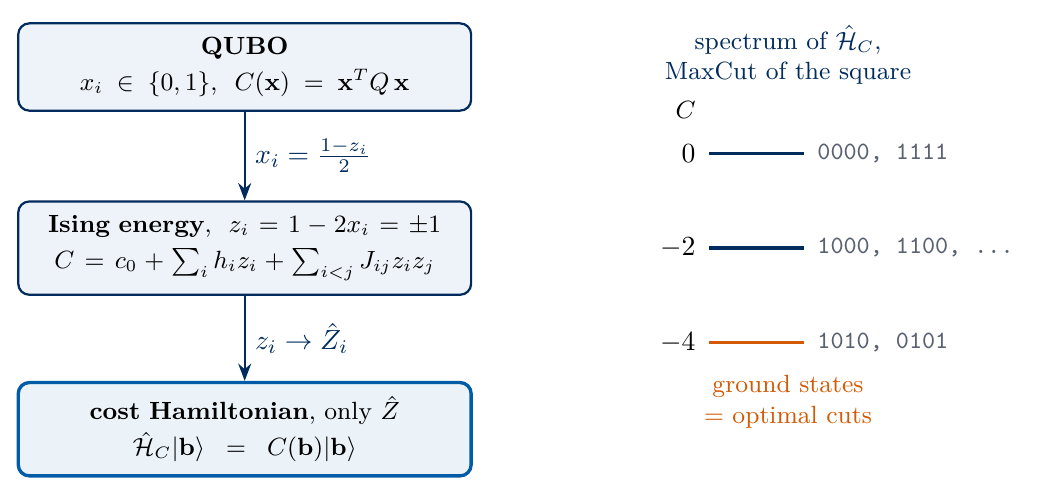

The code applies the general formulas (7) to the matrix $Q$, builds the diagonal of $\hat{\mathcal H}_C$ for all 256 bit strings, and compares it with the cost. It also builds the full $256\times256$ matrix of equation (8) from Kronecker products and checks that it is diagonal.

In [5]:
def qubo_to_ising(Q):
    # equation (7): constant c0, fields h_i, couplings J_ij (i < j)
    S = Q + Q.T
    c0 = Q.sum() / 4 + np.trace(Q) / 4
    h = -S.sum(axis=1) / 4
    J = np.triu(S, k=1) / 4
    return c0, h, J

c0, h, J = qubo_to_ising(Q)
Zsign = 1 - 2 * BITS                                                  # z_i = 1 - 2 b_i, equation (6)
diag_H = c0 + Zsign @ h + np.einsum("ki,ij,kj->k", Zsign, J, Zsign)   # diagonal of equation (8)
assert np.allclose(diag_H, cost, atol=TOL)                            # equation (9) for all 256 bit strings
assert np.allclose(h, 0) and np.isclose(c0, -len(EDGES) / 2)          # equation (10)

def z_on(i):
    ops = [Z if q == i else I2 for q in range(n)]
    out = ops[0]
    for o in ops[1:]:
        out = jnp.kron(out, o)
    return out

Zops = [z_on(i) for i in range(n)]
H_dense = c0 * jnp.eye(2 ** n) + sum(J[i, j] * Zops[i] @ Zops[j] for i in range(n) for j in range(i + 1, n) if J[i, j] != 0)
assert jnp.allclose(H_dense, jnp.diag(jnp.diag(H_dense)), atol=TOL) and np.allclose(np.diag(H_dense), cost)
print(f"c0 = {c0}, all h_i = 0, J_ij = 1/2 on the {len(EDGES)} edges")
print("ground energy of H_C =", diag_H.min(), "= -(maximum cut); ground states:", [fmt(k) for k in np.flatnonzero(diag_H == diag_H.min())][:4], "...")
DIAG = jnp.asarray(diag_H)

c0 = -6.0, all h_i = 0, J_ij = 1/2 on the 12 edges
ground energy of H_C = -10.0 = -(maximum cut); ground states: ['00101101', '01001011', '01011010', '01101001'] ...


The diagonal of the Hamiltonian agrees with the QUBO cost on all 256 bit strings, and the Kronecker-product matrix has no off-diagonal element. The lowest energy is $-10$, the negative of the maximum cut.

## 6. Answers from measured bit strings

A quantum algorithm for a QUBO prepares some state $|\psi\rangle=\sum_{\mathbf b}\psi_{\mathbf b}|\mathbf b\rangle$ and measures all qubits in the computational basis. Each shot returns one bit string $\mathbf b$ with probability $|\psi_{\mathbf b}|^2$, which is one candidate solution, and its cost $C(\mathbf b)$ is evaluated on a classical computer in a time that grows only polynomially with $N$. From $M$ shots we keep the best bit string. The state is useful when its weight on optimal or near-optimal bit strings is much larger than the uniform weight $2^{-N}$ of random guessing. If the optimal bit strings together carry the probability $P_{\rm opt}$, at least one of $M$ independent shots is optimal with probability
$$P_{\rm hit}(M)=1-(1-P_{\rm opt})^M , \tag{11}$$
and the number of shots needed for a chance of 95 per cent is $M_{95}=\lceil\ln0.05/\ln(1-P_{\rm opt})\rceil$, about $3/P_{\rm opt}$ for small $P_{\rm opt}$.

The variational quantum eigensolver (VQE) uses the same circuits and measurements for a different purpose. There the answer is the ground-state energy, a number estimated as an average over many shots. Here the answer is one sampled bit string. Its cost is known exactly as soon as it has been measured, and the average energy serves only as the training signal for the circuit.

The uniform superposition $|+\rangle^{\otimes N}$, prepared by a Hadamard gate on every qubit, gives every bit string the probability $2^{-N}$, so its shots are uniformly random guesses. We sample 100 shots from it.

In [6]:
@partial(jax.jit, static_argnums=2)
def sample_bits(key, probs, shots):
    # shots measurements of all qubits: indices of bit strings drawn with the given probabilities
    u = jax.random.uniform(key, (shots,)) * jnp.sum(probs)
    return jnp.minimum(jnp.searchsorted(jnp.cumsum(probs), u), probs.shape[0] - 1)

P_OPT_RANDOM = len(opt_idx) / 2 ** n
uniform = jnp.full(2 ** n, 1.0 / 2 ** n)
shots_rand = np.asarray(sample_bits(jax.random.PRNGKey(7302), uniform, 100))
print("first five shots of |+>^n:", [fmt(k) for k in shots_rand[:5]], "cuts", cut[shots_rand[:5]])
print(f"best of 100 random shots: cut {cut[shots_rand].max()}, optimal shots: {int(np.sum(cut[shots_rand] == cut_max))}")
M95 = lambda p: math.ceil(math.log(0.05) / math.log(1 - p))
print(f"random guessing: P_opt = {P_OPT_RANDOM:.4f}, shots for a 95% chance of one optimum: {M95(P_OPT_RANDOM)}")
NUMBERS["POptRandom"] = f"{P_OPT_RANDOM:.4f}"
NUMBERS["MNinetyFiveRandom"] = str(M95(P_OPT_RANDOM))

first five shots of |+>^n: ['10001111', '10101100', '00001010', '00010000', '00001010'] cuts [5 8 6 3 6]
best of 100 random shots: cut 10, optimal shots: 2
random guessing: P_opt = 0.0312, shots for a 95% chance of one optimum: 95


For eight qubits random guessing is still an effective strategy, since about 95 random shots find an optimum with a probability of 95 per cent. The probability of an optimum falls as $2^{-N}$ times the number of optimal strings. A useful quantum state must concentrate its weight on low-cost bit strings so that the number of shots stays small for large $N$.

## 7. The QAOA circuit

The quantum approximate optimisation algorithm [1] prepares such a state with a circuit of $p$ layers, where $p$ plays the role of the depth $L$ of a layered circuit. It starts in $|+\rangle^{\otimes N}$, the uniform superposition of all candidates, and alternates two evolutions. The cost layer is the evolution under the cost Hamiltonian for a time $\gamma_\ell$,
$$\hat U_C(\gamma_\ell)=e^{-i\gamma_\ell\hat{\mathcal H}_C}, \tag{12}$$
and the mixing layer is the evolution under the transverse field $\hat{\mathcal H}_B=\sum_i\hat X_i$ for a time $\beta_\ell$,
$$\hat U_B(\beta_\ell)=e^{-i\beta_\ell\sum_i\hat X_i}=\bigotimes_{i=0}^{N-1}\hat R_x(2\beta_\ell). \tag{13}$$
The QAOA state with $2p$ angles $\boldsymbol\gamma=(\gamma_1,\dots,\gamma_p)$ and $\boldsymbol\beta=(\beta_1,\dots,\beta_p)$ is
$$|\boldsymbol\gamma,\boldsymbol\beta\rangle=\hat U_B(\beta_p)\hat U_C(\gamma_p)\cdots\hat U_B(\beta_1)\hat U_C(\gamma_1)\,|+\rangle^{\otimes N}. \tag{14}$$

The sketch draws the circuit (14), Hadamard gates preparing $|+\rangle^{\otimes N}$, $p$ layers of cost evolution and mixing rotations, and a measurement that returns one candidate bit string.

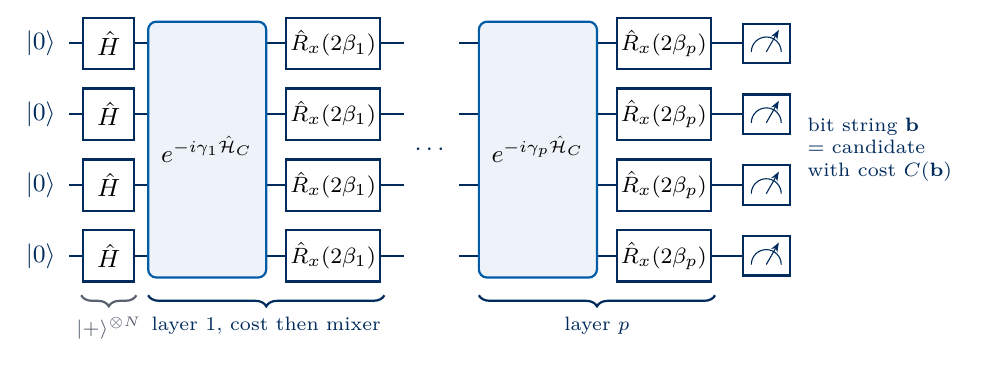

The cost layer is diagonal and multiplies the amplitude of each bit string by the phase $e^{-i\gamma_\ell C(\mathbf b)}$, so bit strings of different cost acquire different phases. The mixing layer rotates every qubit and makes the amplitudes of bit strings that differ by single bit flips interfere. The cost layer alone leaves all probabilities unchanged, and the mixing layer alone leaves $|+\rangle^{\otimes N}$ unchanged, since it is an eigenstate of $\sum_i\hat X_i$. Only the alternation moves probability, and the angles are chosen so that the interference collects it on low-cost bit strings.

In a simulation the cost layer is one element-wise multiplication with the vector of phases. On a device it is compiled into gates, because the terms of equation (8) commute,
$$e^{-i\gamma\hat{\mathcal H}_C}=e^{-i\gamma c_0}\prod_{i<j}\hat R_{zz}(2\gamma J_{ij})\prod_i\hat R_z(2\gamma h_i), \tag{15}$$
with one $\hat R_{zz}$ gate per edge for MaxCut and a global phase that has no effect on any measurement. The trained quantity is the expected cost
$$E(\boldsymbol\gamma,\boldsymbol\beta)=\langle\boldsymbol\gamma,\boldsymbol\beta|\hat{\mathcal H}_C|\boldsymbol\gamma,\boldsymbol\beta\rangle=\sum_{\mathbf b}\big|\langle\mathbf b|\boldsymbol\gamma,\boldsymbol\beta\rangle\big|^2\,C(\mathbf b), \tag{16}$$
the average cost of the measured bit strings, so the expected cut is $-E$. Since $\hat{\mathcal H}_C$ is diagonal, its expectation value is estimated from the same computational-basis shots that deliver the candidates, with a single measurement setting. The code checks the phase form of equation (14) against the gate form (15).

In [7]:
def mixer(psi, beta):
    t = psi.reshape((2,) * n)
    U = rot(X, 2 * beta)                                   # e^{-i beta X} on every qubit, equation (13)
    for q in range(n):
        t = apply_1q(t, U, q)
    return t.reshape(-1)

@jax.jit
def qaoa_state(gammas, betas):
    psi = jnp.full(2 ** n, 1 / np.sqrt(2 ** n), dtype=CDTYPE)    # |+>^n
    def layer(psi, gb):
        g, b = gb
        return mixer(psi * jnp.exp(-1j * g * DIAG), b), None    # cost layer as a phase vector, equation (12)
    psi, _ = lax.scan(layer, psi, (gammas, betas))
    return psi

def energy(angles):
    p = angles.shape[0] // 2
    return jnp.sum(jnp.abs(qaoa_state(angles[:p], angles[p:])) ** 2 * DIAG)      # equation (16)

ZZ_EDGE = [jnp.asarray(zz_signs(n, i, j)) for i, j in EDGES]
def qaoa_state_gates(gammas, betas):
    psi = jnp.full(2 ** n, 1 / np.sqrt(2 ** n), dtype=CDTYPE)
    for g, b in zip(gammas, betas):
        for (i, j), s in zip(EDGES, ZZ_EDGE):
            psi = psi * jnp.exp(-1j * (2 * g * J[i, j]) / 2 * s)   # R_zz(2 gamma J_ij), equation (15)
        psi = mixer(psi, b)
    return psi

g_t, b_t = jnp.array([0.4, 0.9]), jnp.array([-0.3, 0.2])
psi_phase, psi_gates = qaoa_state(g_t, b_t), qaoa_state_gates(g_t, b_t)
overlap = jnp.vdot(psi_phase, psi_gates)
assert abs(abs(overlap) - 1) < 1e-12                         # equal up to the global phase e^{-i gamma c0}
assert abs(np.angle(overlap) - np.angle(np.exp(1j * c0 * float(g_t.sum())))) < 1e-10
print("phase form = gate form up to the global phase; E at test angles =", float(energy(jnp.r_[g_t, b_t])))

phase form = gate form up to the global phase; E at test angles = -6.861627032394337


## 8. Depth one

At $p=1$ the expected cost $E(\gamma,\beta)$ depends on two angles and can be drawn as a map. Three symmetries restrict the angles that need to be scanned. The eigenvalues of $\hat{\mathcal H}_C$ are integers, so $\hat U_C(\gamma+2\pi)=\hat U_C(\gamma)$. A shift $\beta\to\beta+\pi/2$ multiplies the mixing layer by $(-i)^N\prod_i\hat X_i$, which flips every bit, leaves $|+\rangle^{\otimes N}$ and every cut unchanged, and therefore leaves $E$ unchanged. Reversing both angles, $(\gamma,\beta)\to(-\gamma,-\beta)$, complex-conjugates the state and leaves all probabilities unchanged. The rectangle $0\le\gamma\le\pi$, $-\pi/4\le\beta\le\pi/4$ therefore contains every value of $E$. We evaluate $E$ on a grid of $101\times101$ angles with `jax.vmap`.

grid minimum: E = -8.3083 at gamma = 0.628, beta = -0.393; expected cut 8.308


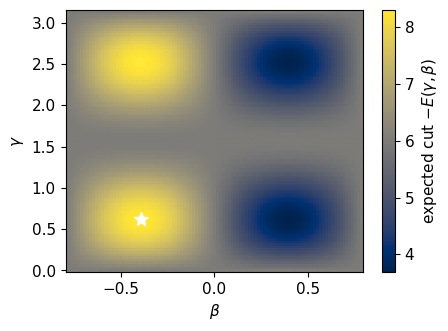

In [8]:
gam = jnp.linspace(0, np.pi, 101)
bet = jnp.linspace(-np.pi / 4, np.pi / 4, 101)
land = jax.jit(jax.vmap(jax.vmap(lambda g, b: energy(jnp.array([g, b])), (None, 0)), (0, None)))(gam, bet)
land = np.asarray(land)                                       # land[i, j] = E(gamma_i, beta_j)
ig, ib = np.unravel_index(np.argmin(land), land.shape)
print(f"grid minimum: E = {land.min():.4f} at gamma = {float(gam[ig]):.3f}, beta = {float(bet[ib]):.3f}; expected cut {-land.min():.3f}")
fig, ax = plt.subplots(figsize=(4.8, 3.4))
im = ax.pcolormesh(np.asarray(bet), np.asarray(gam), -land, cmap="cividis", shading="auto")
ax.plot(float(bet[ib]), float(gam[ig]), "w*", ms=10)
ax.set_xlabel(r"$\beta$"); ax.set_ylabel(r"$\gamma$")
fig.colorbar(im, ax=ax, label=r"expected cut $-E(\gamma,\beta)$")
save(fig, "fig_lab073_landscape"); plt.show()

The colour shows the expected cut $-E(\gamma,\beta)$ of the depth-one state, and the star marks the best grid point. At $\gamma=0$ or $\beta=0$ the state keeps the uniform distribution and the expected cut equals the random value of six edges. The expected cut has its maxima at negative $\beta$, near $\gamma\approx0.6$ and $\gamma\approx2.5$, and its minima at positive $\beta$, where the angles move probability towards small cuts. The best depth-one state cuts slightly more than eight edges on average.

## 9. Deeper circuits trained by gradient descent

For $p>1$ a grid is too expensive, since its size grows as the number of grid points per angle to the power $2p$. We minimise $E(\boldsymbol\gamma,\boldsymbol\beta)$ with gradients from `jax.grad` and the Adam optimiser [2], with 400 steps and the learning rate 0.02. The landscape has several local minima at larger $p$, so we train 16 starting angle sets in parallel with `jax.vmap` and keep the best. Fifteen are random, with $\gamma_\ell\in[0,\pi/2]$ and $\beta_\ell\in[0,\pi/4]$. The sixteenth is a linear ramp,
$$\gamma_\ell=s_\ell\,\delta t,\qquad\beta_\ell=-(1-s_\ell)\,\delta t,\qquad s_\ell=\frac{\ell-1/2}{p}, \tag{17}$$
with $\delta t=0.8$, in which the cost angles grow and the mixing angles shrink in magnitude from the first layer to the last. On a device the gradient comes from the parameter-shift rule, with the energy estimated from shots. Each QAOA angle is shared by several gates. The angle $\gamma_\ell$ enters every gate $\hat R_{zz}(2\gamma_\ell J_{ij})$ of the gate form (15), and $\gamma_\ell$ also enters $\hat R_z(2\gamma_\ell h_i)$ when there are fields, while $\beta_\ell$ enters the $N$ gates $\hat R_x(2\beta_\ell)$. If gate $g$ has the angle $\theta_g=c_g\varphi$ for a shared angle $\varphi$, the chain rule gives $\partial_\varphi E=\sum_gc_g\,\partial_{\theta_g}E$, and each term follows from the two shifted circuits of the parameter-shift rule. For MaxCut, $c_g=2J_{ij}=1$ for the twelve $\hat R_{zz}$ gates of a layer and $c_g=2$ for its eight $\hat R_x$ gates, so the two derivatives of one layer need $2\times(12+8)=40$ circuits and a full gradient $40p$ circuits, each measured with many shots. We judge the trained state by the approximation ratio
$$r=\frac{-E(\boldsymbol\gamma,\boldsymbol\beta)}{\mathrm{cut}_{\max}} \tag{18}$$
which compares the expected cut with the optimum and equals $6/10$ for random guessing. We also use the probability $P_{\rm opt}$ of an optimal bit string, which enters equation (11), and the number $M_{95}$ of shots for a 95 per cent chance of measuring an optimum.

In [9]:
def adam(loss, theta0, steps, lr):
    # Adam with the standard moment decay rates 0.9 and 0.999
    value_and_grad = jax.value_and_grad(loss)
    def step(carry, i):
        th, m, v = carry
        l, g = value_and_grad(th)
        m = 0.9 * m + 0.1 * g
        v = 0.999 * v + 0.001 * g ** 2
        th = th - lr * (m / (1 - 0.9 ** (i + 1))) / (jnp.sqrt(v / (1 - 0.999 ** (i + 1))) + 1e-8)
        return (th, m, v), l
    (th, _, _), hist = lax.scan(step, (theta0, jnp.zeros_like(theta0), jnp.zeros_like(theta0)), jnp.arange(steps))
    return th, hist

def fold(angles):
    # map gamma into (-pi, pi], beta into (-pi/4, pi/4] using the symmetries of Section 8
    p = len(angles) // 2
    g = (np.asarray(angles[:p]) + np.pi) % (2 * np.pi) - np.pi
    b = (np.asarray(angles[p:]) + np.pi / 4) % (np.pi / 2) - np.pi / 4
    if g[0] < 0:
        g, b = -g, -b                                     # time reversal
    return g, b

OPT_MASK = jnp.asarray(cut == cut_max)
STARTS, STEPS, LR, RAMP_DT = 16, 400, 0.02, 0.8
results, states, curves = {}, {}, {}
t_train = time.perf_counter()
for p in (1, 2, 3, 4):
    key = jax.random.PRNGKey(7310 + p)
    th0 = jax.random.uniform(key, (STARTS, 2 * p)) * jnp.r_[jnp.full(p, np.pi / 2), jnp.full(p, np.pi / 4)]
    s_l = (np.arange(1, p + 1) - 0.5) / p
    th0 = th0.at[0].set(jnp.r_[s_l * RAMP_DT, -(1 - s_l) * RAMP_DT])     # linear ramp start, equation (17)
    th, hist = jax.jit(jax.vmap(lambda t: adam(energy, t, STEPS, LR)))(th0)
    hist = np.asarray(hist)
    E_final = np.asarray(jax.vmap(energy)(th))
    i_best = int(np.argmin(E_final))
    g_b, b_b = fold(th[i_best])
    psi = qaoa_state(jnp.asarray(g_b), jnp.asarray(b_b))
    probs = np.asarray(jnp.abs(psi) ** 2)
    E_best = float(np.sum(probs * diag_H))
    assert abs(E_best - E_final[i_best]) < 1e-10               # folding the angles leaves E unchanged
    p_opt = float(probs[np.asarray(OPT_MASK)].sum())
    results[p] = dict(E=E_best, ratio=-E_best / cut_max, P_opt=p_opt, M95=M95(p_opt),
                      gammas=g_b.tolist(), betas=b_b.tolist(), starts_within_1e3=int(np.sum(E_final < E_best + 1e-3)))
    states[p], curves[p] = probs, hist[i_best]
print(f"training of 4 x {STARTS} circuits: {time.perf_counter() - t_train:.1f} s")
assert results[1]["E"] <= land.min() + 1e-9                   # depth one: at least as good as the best grid point
print(" p | expected cut | ratio r | P_opt  | M_95 | gamma_l                       | beta_l")
print(f" random guess |   {cut.mean():.3f}     |  {cut.mean() / cut_max:.3f}  | {P_OPT_RANDOM:.4f} | {M95(P_OPT_RANDOM):4d} |")
for p, r in results.items():
    print(f" {p} |   {-r['E']:.3f}     |  {r['ratio']:.3f}  | {r['P_opt']:.4f} | {r['M95']:4d} | "
          f"{np.round(r['gammas'], 3)} | {np.round(r['betas'], 3)}")
WORDS = {1: "One", 2: "Two", 3: "Three", 4: "Four"}
for p, r in results.items():
    NUMBERS[f"RatioP{WORDS[p]}"] = f"{r['ratio']:.3f}"
    NUMBERS[f"ExpCutP{WORDS[p]}"] = f"{-r['E']:.2f}"
    NUMBERS[f"POptP{WORDS[p]}"] = f"{r['P_opt']:.3f}"
    NUMBERS[f"MNinetyFiveP{WORDS[p]}"] = str(r["M95"])

training of 4 x 16 circuits: 14.5 s
 p | expected cut | ratio r | P_opt  | M_95 | gamma_l                       | beta_l
 random guess |   6.000     |  0.600  | 0.0312 |   95 |
 1 |   8.309     |  0.831  | 0.3217 |    8 | [0.615] | [-0.393]
 2 |   9.248     |  0.925  | 0.5220 |    5 | [0.446 0.807] | [-0.539 -0.303]
 3 |   9.658     |  0.966  | 0.7700 |    3 | [0.428 0.771 1.009] | [-0.586 -0.441 -0.212]
 4 |   9.830     |  0.983  | 0.9090 |    2 | [0.351 0.707 0.936 1.105] | [-0.564 -0.428 -0.261 -0.118]


The table lists, for each depth, the expected cut, the approximation ratio (18), the probability of an optimal bit string, the shots needed to find one with a probability of 95 per cent, and the trained angles mapped into the ranges of Section 8. Gradient descent at $p=1$ reaches the best point of the grid. Each further layer raises the approximation ratio and the probability of the optimum, which grows from $1/32$ for random guessing to about one third at $p=1$ and to about $0.9$ at $p=4$. The number of shots needed to see an optimum falls accordingly from about a hundred to two.

In the deeper circuits, the trained cost angles $\gamma_\ell$ grow from the first layer to the last, and the mixing angles $\beta_\ell$ are negative and shrink in magnitude towards zero. The circuit therefore starts with mostly mixing and ends with mostly cost evolution, the schedule of the slow evolution discussed in Section 14. The figure collects the measures of quality against depth and shows how the trained state distributes its probability over cut sizes.

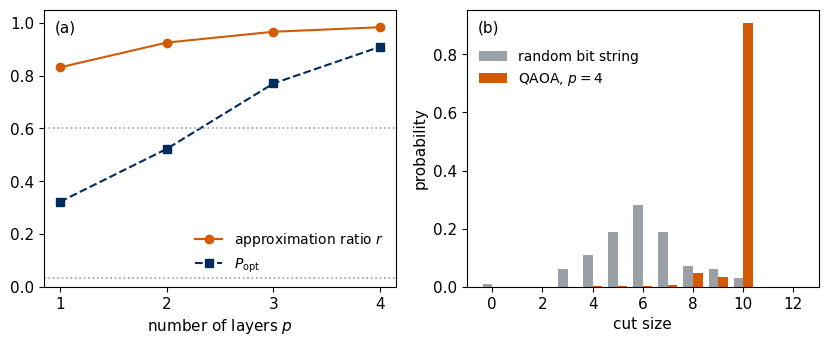

In [10]:
ps = np.array(sorted(results))
cut_vals = np.arange(len(EDGES) + 1)
fig, axs = plt.subplots(1, 2, figsize=(10.0, 3.6))
axs[0].plot(ps, [results[p]["ratio"] for p in ps], "o-", color=COL["qaoa"], label=r"approximation ratio $r$")
axs[0].plot(ps, [results[p]["P_opt"] for p in ps], "s--", color=COL["opt"], label=r"$P_{\rm opt}$")
axs[0].axhline(cut.mean() / cut_max, color=COL["rand"], ls=":", lw=1.2)
axs[0].axhline(P_OPT_RANDOM, color=COL["rand"], ls=":", lw=1.2)
axs[0].set_xticks(ps); axs[0].set_xlabel("number of layers $p$"); axs[0].set_ylim(0, 1.05)
axs[0].legend(frameon=False, fontsize=10, loc="lower right")
w = 0.38
dist_rand = np.bincount(cut, minlength=len(cut_vals)) / 2 ** n
dist_q = np.array([states[4][cut == c].sum() for c in cut_vals])
axs[1].bar(cut_vals - w / 2, dist_rand, width=w, color=COL["rand"], label="random bit string")
axs[1].bar(cut_vals + w / 2, dist_q, width=w, color=COL["qaoa"], label="QAOA, $p=4$")
axs[1].set_xlabel("cut size"); axs[1].set_ylabel("probability"); axs[1].set_xticks(range(0, 13, 2)); axs[1].legend(frameon=False, fontsize=10, loc="upper left", bbox_to_anchor=(0.0, 0.9))
for a, lab in zip(axs, "ab"):
    a.text(0.03, 0.92, f"({lab})", transform=a.transAxes)
save(fig, "fig_lab073_depth"); plt.show()

Panel (a) shows the approximation ratio (circles) and the probability of an optimal bit string (squares) of the trained QAOA states against the number of layers, and the dotted lines mark the random-guessing values $0.6$ and $1/32$. Panel (b) compares the exact probability of each cut size for a uniformly random bit string (grey) with the trained $p=4$ state (orange). The QAOA state moves almost all its weight to the maximum cut of ten edges, whereas random guessing spreads it around six.

## 10. Sampling the trained circuits

A device gives the distribution of panel (b) only through shots. We measure the trained $p=4$ state $M=1000$ times, compute the cut of every measured bit string, and keep the best one. From the same shots we estimate the expected cost (16) as the mean $\bar C=\frac1M\sum_{s=1}^MC(\mathbf b^{(s)})$ with its standard error $\sigma_{\bar C}=\sigma_C/\sqrt M$, where $\sigma_C$ is the sample standard deviation of the costs. The same number of uniformly random bit strings serves as the comparison. Finally we follow the cut of the best bit string found so far as the number of shots grows, for both sources.

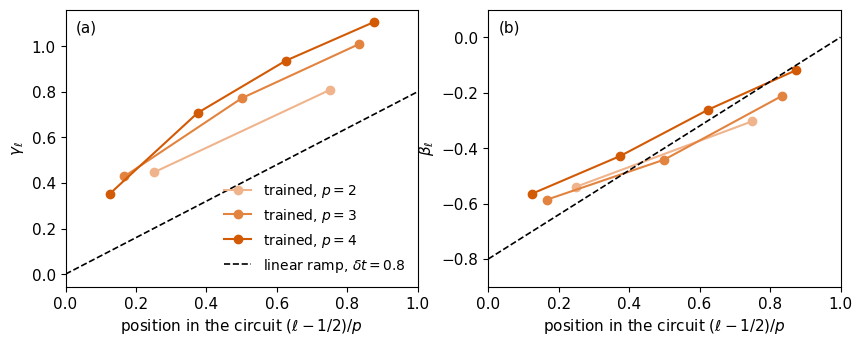

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(10.0, 3.6))
s_line = np.linspace(0, 1, 50)
shades = {2: "#F0B48C", 3: "#E2833F", 4: "#D35A05"}
for p in (2, 3, 4):
    s_l = (np.arange(1, p + 1) - 0.5) / p
    axs[0].plot(s_l, results[p]["gammas"], "o-", color=shades[p], label=f"trained, $p={p}$")
    axs[1].plot(s_l, results[p]["betas"], "o-", color=shades[p], label=f"trained, $p={p}$")
axs[0].plot(s_line, s_line * RAMP_DT, "k--", lw=1.2, label=r"linear ramp, $\delta t=0.8$")
axs[1].plot(s_line, -(1 - s_line) * RAMP_DT, "k--", lw=1.2, label=r"linear ramp, $\delta t=0.8$")
axs[0].set_ylabel(r"$\gamma_\ell$"); axs[1].set_ylabel(r"$\beta_\ell$")
for a, lab in zip(axs, "ab"):
    a.set_xlabel(r"position in the circuit $(\ell-1/2)/p$"); a.set_xlim(0, 1)
    a.text(0.03, 0.92, f"({lab})", transform=a.transAxes)
axs[0].legend(frameon=False, loc="lower right"); axs[1].set_ylim(-0.9, 0.1)
save(fig, "fig_lab073_qaoa_angles"); plt.show()

The figure draws the trained angles of the best circuits at $p=2$, 3 and 4 against the relative position $(\ell-1/2)/p$ of the layer, panel (a) for the cost angles $\gamma_\ell$ and panel (b) for the mixing angles $\beta_\ell$, mapped into the ranges of Section 8. The dashed lines show the linear ramp (17). The trained cost angles grow along the circuit and the mixing angles approach zero from below, as in the ramp, while their values at a given depth deviate from the straight lines. Section 14 explains this pattern through adiabatic evolution.

QAOA p = 4, 1000 shots: estimated E = -9.870 +- 0.016, exact -9.830
fraction of optimal shots: QAOA 0.927 (exact 0.909), random 0.034
first optimal shot: QAOA shot 2, random shot 26
best bit string from the QAOA shots: 11010010 with cut 10


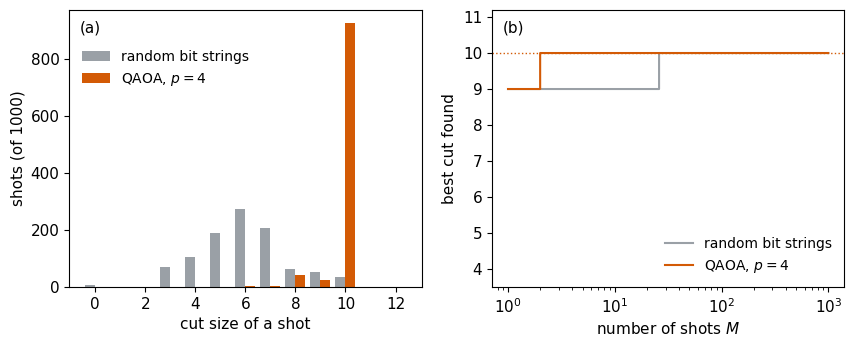

In [12]:
M_SHOTS = 1000
k1, k2 = jax.random.split(jax.random.PRNGKey(7320))
idx_q = np.asarray(sample_bits(k1, jnp.asarray(states[4]), M_SHOTS))
idx_r = np.asarray(sample_bits(k2, uniform, M_SHOTS))
cq, cr = cut[idx_q], cut[idx_r]
C_bar, C_se = float(np.mean(-cq)), float(np.std(-cq, ddof=1) / np.sqrt(M_SHOTS))
print(f"QAOA p = 4, {M_SHOTS} shots: estimated E = {C_bar:.3f} +- {C_se:.3f}, exact {results[4]['E']:.3f}")
print(f"fraction of optimal shots: QAOA {np.mean(cq == cut_max):.3f} (exact {results[4]['P_opt']:.3f}), random {np.mean(cr == cut_max):.3f}")
first_q = int(np.argmax(cq == cut_max)) + 1
first_r = int(np.argmax(cr == cut_max)) + 1 if np.any(cr == cut_max) else None
print(f"first optimal shot: QAOA shot {first_q}, random shot {first_r}")
print("best bit string from the QAOA shots:", fmt(idx_q[np.argmax(cq)]), "with cut", cq.max())
assert abs(C_bar - results[4]["E"]) < 5 * C_se
NUMBERS["Shots"] = str(M_SHOTS)
NUMBERS["EstEnergyPFour"] = f"{C_bar:.3f}"
NUMBERS["EstEnergySEPFour"] = f"{C_se:.3f}"
NUMBERS["FracOptQAOA"] = f"{np.mean(cq == cut_max):.3f}"
NUMBERS["FracOptRandom"] = f"{np.mean(cr == cut_max):.3f}"
NUMBERS["FirstOptRandom"] = str(first_r)

fig, axs = plt.subplots(1, 2, figsize=(10.0, 3.6))
axs[0].hist([cr, cq], bins=np.arange(len(EDGES) + 2) - 0.5, color=[COL["rand"], COL["qaoa"]],
            label=["random bit strings", "QAOA, $p=4$"])
axs[0].set_xlabel("cut size of a shot"); axs[0].set_xticks(range(0, 13, 2)); axs[0].set_ylabel(f"shots (of {M_SHOTS})")
axs[0].legend(frameon=False, fontsize=10, loc="upper left", bbox_to_anchor=(0.0, 0.9))
shots_axis = np.arange(1, M_SHOTS + 1)
axs[1].step(shots_axis, np.maximum.accumulate(cr), where="post", color=COL["rand"], label="random bit strings")
axs[1].step(shots_axis, np.maximum.accumulate(cq), where="post", color=COL["qaoa"], label="QAOA, $p=4$")
axs[1].axhline(cut_max, color=COL["cut"], ls=":", lw=1)
axs[1].set_xscale("log"); axs[1].set_ylim(3.5, 11.2); axs[1].set_xlabel("number of shots $M$"); axs[1].set_ylabel("best cut found")
axs[1].legend(frameon=False, fontsize=10, loc="lower right")
for a, lab in zip(axs, "ab"):
    a.text(0.03, 0.92, f"({lab})", transform=a.transAxes)
save(fig, "fig_lab073_samples"); plt.show()

Panel (a) is the histogram of the cut sizes of the 1000 measured bit strings, for the trained QAOA state and for random bit strings. Panel (b) shows the best cut found among the first $M$ shots, with the dotted line at the maximum cut. The estimate of the expected cost from the shots lies within three standard errors of the exact value, so the training signal is available from the same records. An optimal bit string appears in the second QAOA shot, whereas the first optimal random bit string is shot 26. Both sources find the optimum within the 1000 shots, which is expected for eight qubits, where $2^N$ is small. For applications the relevant quantity is the growth of the required number of shots with $N$. It is exponential for random guessing, and for the QAOA it depends on the problem class and on how the depth $p$ must grow with $N$.

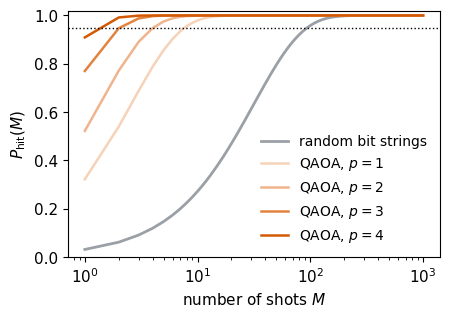

In [13]:
M_axis = np.unique(np.logspace(0, 3, 200).astype(int))
fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.plot(M_axis, 1 - (1 - P_OPT_RANDOM) ** M_axis, color=COL["rand"], lw=2, label="random bit strings")
for p, shade in zip((1, 2, 3, 4), ("#F6D2B8", "#F0B48C", "#E2833F", "#D35A05")):
    ax.plot(M_axis, 1 - (1 - results[p]["P_opt"]) ** M_axis, color=shade, lw=1.8, label=f"QAOA, $p={p}$")
ax.axhline(0.95, color="k", ls=":", lw=1)
ax.set_xscale("log"); ax.set_ylim(0, 1.02)
ax.set_xlabel("number of shots $M$"); ax.set_ylabel(r"$P_{\rm hit}(M)$")
ax.legend(frameon=False, loc="lower right", fontsize=10)
save(fig, "fig_lab073_hit_probability"); plt.show()

The figure evaluates equation (11) with the exact probabilities $P_{\rm opt}$ of the trained states and of random guessing. It shows the probability $P_{\rm hit}(M)$ that at least one of $M$ shots is an optimal bit string, and the dotted line marks 95 per cent. Each added layer shifts the curve to fewer shots, from about 95 shots for random bit strings to two shots at $p=4$, the values $M_{95}$ of the table in Section 9.

## 11. Number partitioning

A list of positive integers $a_0,\dots,a_{N-1}$ is to be divided into two groups whose sums are equal, or as close to equal as possible. Two movers sharing boxes of different weights, or two processors sharing jobs of different durations, face this problem. For the six numbers $3,1,1,2,2,1$ with the total 10, the groups $\{3,2\}$ and $\{1,1,2,1\}$ both sum to 5, a perfect partition, whereas moving the 3 into the second group gives the sums 2 and 8. Number partitioning is on Karp's list of NP-complete problems [4].

The sketch shows the perfect partition $\mathbf b=100100$ of the numbers $3,1,1,2,2,1$, with both groups summing to 5 and the residual zero.

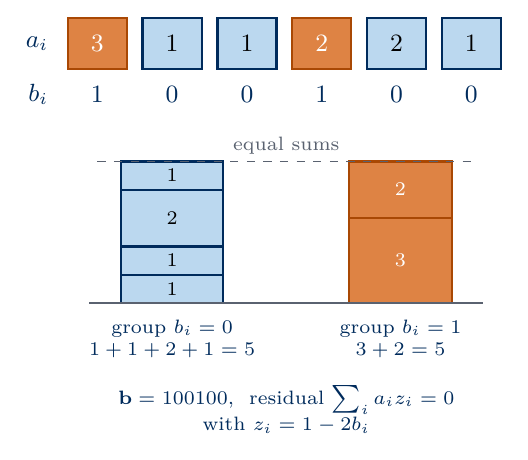

We label the group of number $i$ by the bit $b_i$ and its spin $z_i=1-2b_i$. The difference between the two group sums is the residual $\sum_ia_iz_i$, and the cost is its square,
$$C(\mathbf b)=\Big(\sum_{i=0}^{N-1}a_iz_i\Big)^2=\sum_ia_i^2+2\sum_{i<j}a_ia_j\,z_iz_j , \tag{19}$$
where $z_i^2=1$ turns the diagonal terms into a constant. The cost Hamiltonian is therefore
$$\hat{\mathcal H}_C=\sum_{i<j}J_{ij}\,\hat Z_i\hat Z_j+\Big(\sum_ia_i^2\Big)\hat I,\qquad J_{ij}=2a_ia_j , \tag{20}$$
with no fields. In the binary variables $x_i=b_i=(1-z_i)/2$ the same cost is a QUBO plus a constant. With $A=\sum_ia_i$ and $x_i^2=x_i$, the residual is $A-2\sum_ia_ix_i$, and squaring it gives
$$C=A^2+\mathbf x^TQ\,\mathbf x,\qquad Q_{ij}=4a_ia_j\ (i\neq j),\qquad Q_{ii}=4a_i^2-4Aa_i . \tag{21}$$
The general formulas (7) applied to this matrix return the couplings (20) and vanishing fields, which the code checks.

Every pair of numbers is coupled, so the interaction graph is complete, with $N(N-1)/2=28$ couplings of strengths proportional to $a_ia_j$, compared with twelve equal couplings for the MaxCut graph. A perfect partition has the cost zero, so the approximation ratio (18), defined relative to the optimal cost, is meaningless. We judge a state by the probability $P_{\rm opt}$ of a perfect partition and by the mean absolute residual $\langle|\sum_ia_iz_i|\rangle$. Perfect partitions are also highly degenerate. For the instance $2,1,2,1,2,1,2,1$ with the total 12, a group of sum 6 contains two 2's and two 1's ($6\times6=36$ choices), three 2's (4 choices) or one 2 and four 1's (4 choices). Hence 44 of the 256 bit strings are perfect partitions, and random guessing finds one with probability $44/256\approx0.17$.

The residual is always even for this instance, so every cost is a multiple of 4. The cost layer $e^{-i\gamma\hat{\mathcal H}_C}$ is then periodic in $\gamma$ with the period $\pi/2$, four times shorter than for MaxCut, and with the reversal $(\gamma,\beta)\to(-\gamma,-\beta)$ the range $0\le\gamma\le\pi/4$ contains every value of the expected cost. The code checks equations (19) to (21) on all bit strings, counts the perfect partitions, and evaluates the depth-one landscape on this range. Costs up to 144 make the phases $\gamma C(\mathbf b)$ change on the scale $2\pi/144\approx0.04$ in $\gamma$, so the grid uses 401 values of $\gamma$, with a spacing of 0.002.

example 3,1,1,2,2,1: 10 of 64 bit strings are perfect partitions, e.g. 000111
|residual| : [ 0  2  4  6  8 10 12] 
bit strings: [44 80 62 40 20  8  2]
perfect partitions: 44 of 256, random P_opt = 0.172, mean |residual| of a random string = 3.562
depth-one landscape: smallest expected cost 4.991 (uniform state: 20.0)


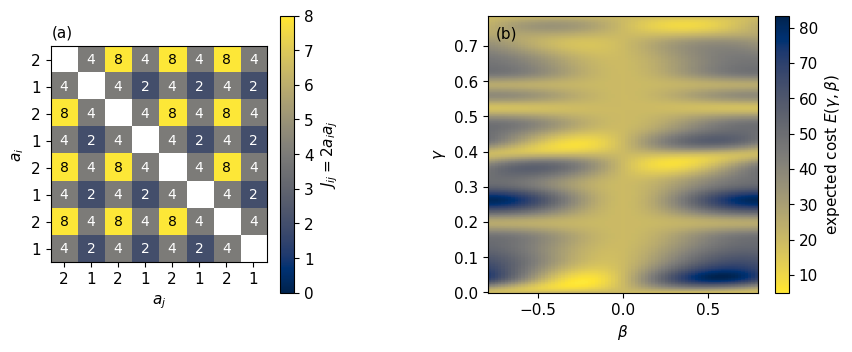

In [14]:
# the six-number example, solved by enumeration
small = np.array([3, 1, 1, 2, 2, 1])
small_res = (1 - 2 * bit_table(6)) @ small
print(f"example 3,1,1,2,2,1: {int(np.sum(small_res == 0))} of 64 bit strings are perfect partitions, e.g.",
      "".join(map(str, bit_table(6)[np.argmax(small_res == 0)])))

A_NUM = np.array([2, 1, 2, 1, 2, 1, 2, 1])
A_TOT = int(A_NUM.sum())
resid = Zsign @ A_NUM                                                  # residual sum_i a_i z_i of every bit string
cost_np = resid.astype(float) ** 2                                     # equation (19)
Q_np = 4.0 * np.outer(A_NUM, A_NUM)
np.fill_diagonal(Q_np, 4 * A_NUM ** 2 - 4 * A_TOT * A_NUM)             # equation (21)
assert np.allclose(np.einsum("ki,ij,kj->k", BITS, Q_np, BITS) + A_TOT ** 2, cost_np)
c0_np, h_np, J_np = qubo_to_ising(Q_np)
assert np.allclose(h_np, 0) and np.allclose(J_np, np.triu(2 * np.outer(A_NUM, A_NUM), 1))   # equation (20)
diag_np = c0_np + A_TOT ** 2 + np.einsum("ki,ij,kj->k", Zsign, J_np, Zsign)
assert np.allclose(diag_np, cost_np) and np.all(cost_np % 4 == 0)
perfect = cost_np == 0
P_OPT_NP_RANDOM = float(perfect.mean())
vals, cnts = np.unique(np.abs(resid), return_counts=True)
print("|residual| :", vals, "\nbit strings:", cnts)
print(f"perfect partitions: {int(perfect.sum())} of 256, random P_opt = {P_OPT_NP_RANDOM:.3f}, "
      f"mean |residual| of a random string = {np.abs(resid).mean():.3f}")
NUMBERS["NPPerfect"] = str(int(perfect.sum()))
NUMBERS["NPPOptRandom"] = f"{P_OPT_NP_RANDOM:.3f}"
NUMBERS["NPMeanResidRandom"] = f"{np.abs(resid).mean():.2f}"
DIAG_NP = jnp.asarray(cost_np)

@jax.jit
def qaoa_probs_d(gammas, betas, diag):
    # QAOA state (14) for any diagonal cost vector; returns the probabilities of all bit strings
    psi = jnp.full(2 ** n, 1 / np.sqrt(2 ** n), dtype=CDTYPE)
    def layer(psi, gb):
        g, b = gb
        return mixer(psi * jnp.exp(-1j * g * diag), b), None
    psi, _ = lax.scan(layer, psi, (gammas, betas))
    return jnp.abs(psi) ** 2

def energy_d(angles, diag):
    p = angles.shape[0] // 2
    return jnp.sum(qaoa_probs_d(angles[:p], angles[p:], diag) * diag)

assert abs(float(energy_d(jnp.array([0.4, -0.3]), DIAG)) - float(energy(jnp.array([0.4, -0.3])))) < 1e-12

gam_np = jnp.linspace(0, np.pi / 4, 401)              # spacing 0.002, well below the scale 2 pi / 144
bet_np = jnp.linspace(-np.pi / 4, np.pi / 4, 81)
land_np = np.asarray(jax.jit(jax.vmap(jax.vmap(lambda g, b: energy_d(jnp.array([g, b]), DIAG_NP), (None, 0)), (0, None)))(gam_np, bet_np))

fig, axs = plt.subplots(1, 2, figsize=(10.0, 3.6), gridspec_kw={"width_ratios": [1, 1.25]})
Jmat = 2.0 * np.outer(A_NUM, A_NUM).astype(float)
np.fill_diagonal(Jmat, np.nan)                                         # no self-coupling
imJ = axs[0].imshow(Jmat, cmap="cividis", vmin=0, vmax=8)
for i in range(n):
    for j in range(n):
        if i != j:
            axs[0].text(j, i, f"{int(Jmat[i, j])}", ha="center", va="center", fontsize=10, color="w" if Jmat[i, j] < 5 else "k")
axs[0].set_xticks(range(n)); axs[0].set_yticks(range(n))
axs[0].set_xticklabels([f"{a}" for a in A_NUM]); axs[0].set_yticklabels([f"{a}" for a in A_NUM])
axs[0].set_xlabel(r"$a_j$"); axs[0].set_ylabel(r"$a_i$")
fig.colorbar(imJ, ax=axs[0], label=r"$J_{ij}=2a_ia_j$")
axs[0].text(-0.45, -0.85, "(a)", fontsize=11)
fig.subplots_adjust(wspace=0.55)
im = axs[1].pcolormesh(np.asarray(bet_np), np.asarray(gam_np), land_np, cmap="cividis_r", shading="auto")
fig.colorbar(im, ax=axs[1], label=r"expected cost $E(\gamma,\beta)$")
axs[1].set_xlabel(r"$\beta$"); axs[1].set_ylabel(r"$\gamma$")
axs[1].text(0.03, 0.92, "(b)", transform=axs[1].transAxes, color="k")
save(fig, "fig_lab073_partition_graph"); plt.show()
print(f"depth-one landscape: smallest expected cost {land_np.min():.3f} (uniform state: {cost_np.mean():.1f})")

Panel (a) shows the couplings $J_{ij}=2a_ia_j$ of the instance as a matrix, with the numbers $a_i$ as row and column labels. Every entry off the diagonal is nonzero, so the interaction graph is the complete graph on eight vertices, and pairs of large numbers are coupled four times more strongly than pairs of small ones. Panel (b) shows the expected cost of the depth-one state for $0\le\gamma\le\pi/4$, with bright colours for low cost. The MaxCut map changes on the scale of one radian in $\gamma$, whereas this landscape changes on the scale of 0.1 and has several separated low-cost regions, because the cost layer combines the phases $\gamma C(\mathbf b)$ of many different costs.

We train the QAOA at depths one to four with the same settings as in Section 9, from 16 random starts with $\gamma_\ell\in[0,\pi/4]$. One compiled training function per depth serves this problem and the next one, since only the vector of costs changes.

training of 4 x 16 circuits: 8.8 s
 p | expected cost | mean |residual| | P_opt | M_95
 random  |   20.000    |      3.562      | 0.172 |  16
 1       |    4.980    |      1.592      | 0.373 |   7
 2       |    2.893    |      1.139      | 0.484 |   5
 3       |    2.793    |      1.108      | 0.494 |   5
 4       |    2.097    |      0.906      | 0.568 |   4
1000 shots at p = 4: perfect fraction QAOA 0.548, random 0.181; first perfect shot: QAOA 1, random 17


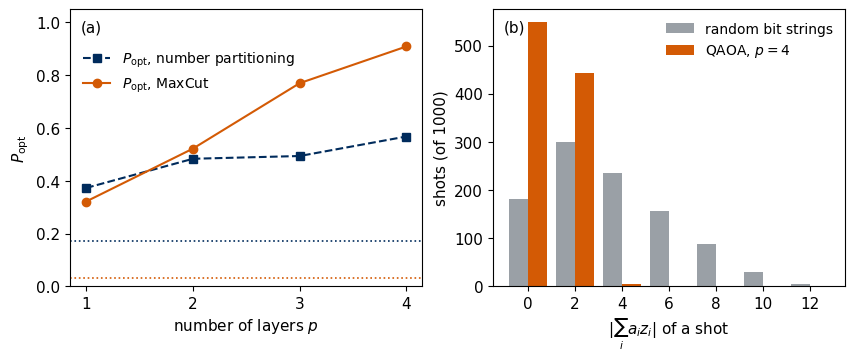

In [15]:
_TRAINERS = {}
def train_qaoa(diag, p, key, gamma_max):
    # STARTS random starts trained in parallel; the trainer of depth p is compiled once and reused for any cost vector
    if p not in _TRAINERS:
        _TRAINERS[p] = jax.jit(jax.vmap(lambda t, d: adam(lambda x: energy_d(x, d), t, STEPS, LR)[0], (0, None)))
    th0 = jax.random.uniform(key, (STARTS, 2 * p)) * jnp.r_[jnp.full(p, gamma_max), jnp.full(p, np.pi / 4)]
    th = _TRAINERS[p](th0, diag)
    E = np.asarray(jax.vmap(energy_d, (0, None))(th, diag))
    best = int(np.argmin(E))
    return np.asarray(th[best]), np.asarray(qaoa_probs_d(th[best][:p], th[best][p:], diag)), float(E[best])

t_np = time.perf_counter()
res_np, states_np = {}, {}
for p in (1, 2, 3, 4):
    th_b, probs, E_b = train_qaoa(DIAG_NP, p, jax.random.PRNGKey(7330 + p), np.pi / 4)
    p_opt = float(probs[perfect].sum())
    res_np[p] = dict(E=E_b, P_opt=p_opt, mean_abs_residual=float(np.sum(probs * np.abs(resid))), M95=M95(p_opt))
    states_np[p] = probs
print(f"training of 4 x {STARTS} circuits: {time.perf_counter() - t_np:.1f} s")
print(" p | expected cost | mean |residual| | P_opt | M_95")
print(f" random  |   {cost_np.mean():6.3f}    |      {np.abs(resid).mean():.3f}      | {P_OPT_NP_RANDOM:.3f} | {M95(P_OPT_NP_RANDOM):3d}")
for p, r in res_np.items():
    print(f" {p}       |   {r['E']:6.3f}    |      {r['mean_abs_residual']:.3f}      | {r['P_opt']:.3f} | {r['M95']:3d}")
    NUMBERS[f"NPPOptP{WORDS[p]}"] = f"{r['P_opt']:.3f}"
    NUMBERS[f"NPResidP{WORDS[p]}"] = f"{r['mean_abs_residual']:.2f}"

k1, k2 = jax.random.split(jax.random.PRNGKey(7335))
idx_np = np.asarray(sample_bits(k1, jnp.asarray(states_np[4]), M_SHOTS))
idx_np_r = np.asarray(sample_bits(k2, uniform, M_SHOTS))
rq, rr = np.abs(resid[idx_np]), np.abs(resid[idx_np_r])
first_np = int(np.argmax(rq == 0)) + 1
first_np_r = int(np.argmax(rr == 0)) + 1
print(f"{M_SHOTS} shots at p = 4: perfect fraction QAOA {np.mean(rq == 0):.3f}, random {np.mean(rr == 0):.3f};"
      f" first perfect shot: QAOA {first_np}, random {first_np_r}")
NUMBERS["NPFracPerfectQAOA"] = f"{np.mean(rq == 0):.3f}"
NUMBERS["NPFracPerfectRandom"] = f"{np.mean(rr == 0):.3f}"

fig, axs = plt.subplots(1, 2, figsize=(10.0, 3.6))
ps_np = np.array(sorted(res_np))
axs[0].plot(ps_np, [res_np[p]["P_opt"] for p in ps_np], "s--", color=COL["opt"], label=r"$P_{\rm opt}$, number partitioning")
axs[0].plot(ps, [results[p]["P_opt"] for p in ps], "o-", color=COL["qaoa"], label=r"$P_{\rm opt}$, MaxCut")
axs[0].axhline(P_OPT_NP_RANDOM, color=COL["opt"], ls=":", lw=1.2)
axs[0].axhline(P_OPT_RANDOM, color=COL["qaoa"], ls=":", lw=1.2)
axs[0].set_xticks(ps_np); axs[0].set_xlabel("number of layers $p$"); axs[0].set_ylabel(r"$P_{\rm opt}$"); axs[0].set_ylim(0, 1.05)
axs[0].legend(frameon=False, fontsize=10, loc="upper left", bbox_to_anchor=(0.0, 0.9))
axs[1].hist([rr, rq], bins=np.arange(0, 15, 2) - 1, color=[COL["rand"], COL["qaoa"]], label=["random bit strings", "QAOA, $p=4$"])
axs[1].set_xticks(range(0, 13, 2)); axs[1].set_xlabel(r"$|\sum_i a_iz_i|$ of a shot"); axs[1].set_ylabel(f"shots (of {M_SHOTS})")
axs[1].legend(frameon=False, fontsize=10, loc="upper right")
for a, lab in zip(axs, "ab"):
    a.text(0.03, 0.92, f"({lab})", transform=a.transAxes)
save(fig, "fig_lab073_partition_qaoa"); plt.show()

The table and panel (a) show that training raises the probability of a perfect partition above the random value, from about 0.17 to about 0.57 at four layers, and lowers the mean absolute residual. Panel (a) also repeats the MaxCut values, and the dotted lines mark the random-guessing probabilities of the two problems. The gain over random guessing is much smaller for number partitioning, since random guessing already succeeds often with 44 perfect bit strings. Beyond $p=1$ the probability of a perfect partition grows slowly with depth. Panel (b) compares the residuals of 1000 shots of the $p=4$ state with those of 1000 random bit strings. The trained state removes all residuals above 4 and puts almost all the weight that misses a perfect partition on the residual 2, the nearest imperfect split. The first QAOA shot is already a perfect partition, and the first perfect random bit string is shot 17.

The core route ends here.

## 12. Maximum independent set

An independent set of a graph is a set of vertices of which no two are joined by an edge. Radio transmitters on a map give the picture, with an edge joining two sites close enough to interfere, and we want to switch on as many transmitters as possible without switching on two neighbours. The maximum independent set (MIS) problem asks for the largest such set. An independent set is called maximal when no vertex can be added to it, and maximum when no independent set is larger. Every maximum set is maximal, whereas a maximal set can be smaller than the maximum. In a star with four leaves the centre alone is a maximal independent set of size one and the four leaves form the maximum one. On a ring of four vertices, the sets $\{0,2\}$ and $\{1,3\}$, the bit strings $1010$ and $0101$, are independent sets of the largest possible size two. On a ring of five vertices any three chosen vertices include two neighbours, so the maximum is two as well, because the odd cycle prevents alternation. A set is independent precisely when it is a clique, a set of mutually joined vertices, of the complement graph. The clique problem is on Karp's list [4], so MIS is NP-complete in its decision form.

The sketch shows a maximum independent set of a ring of six vertices, the alternating set $101010$ of size three, together with the blockade radius of one chosen vertex.

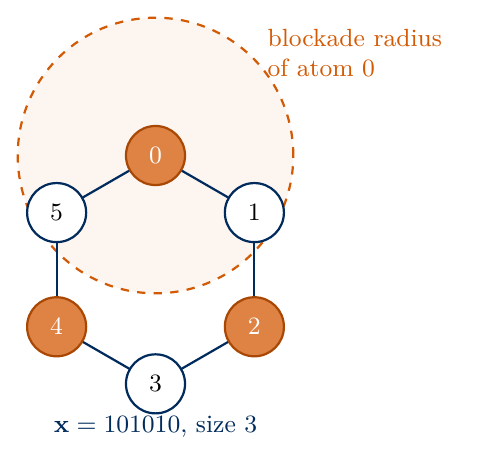

The independence condition is a constraint, which a QUBO does not have. We add it to the cost as a penalty,
$$C(\mathbf x)=-\sum_ix_i+B\sum_{(i,j)\in E}x_ix_j , \tag{22}$$
where the first term counts the chosen vertices and the second counts the violated edges with the penalty weight $B>0$. For $B>1$ every minimiser of (22) is an independent set. Removing one endpoint of a violated edge raises the first term by one and lowers the penalty by at least $B$, so it changes the cost by at most $1-B<0$. A string with a violated edge therefore cannot be optimal. On independent sets the penalty vanishes and the cost is minus the size, so the minimisers are the maximum independent sets. The QUBO matrix has $Q_{ii}=-1$ and $Q_{ij}=Q_{ji}=B/2$ on the edges, and equation (7) gives
$$J_{ij}=\frac B4\ \ \text{on the edges},\qquad h_i=\frac{2-Bd_i}{4} . \tag{23}$$
The fields are nonzero, unlike for MaxCut, because the cost (22) favours $x_i=1$ over $x_i=0$ and is therefore not invariant under flipping all bits.

Arrays of neutral atoms excited to Rydberg states realise the constraint without any penalty. Two atoms closer than the blockade radius cannot both be excited, because their strong interaction shifts the doubly excited state out of resonance with the laser. If the atoms sit at the vertices of a graph whose edges join atoms within the blockade radius, the laser drive reaches only independent sets, with the excited atoms as the chosen vertices. Ref. [6] proposed to find maximum independent sets this way, and Ref. [7] carried it out with arrays of up to 289 atoms in two dimensions.

The sketch shows the blockade of two atoms closer than the blockade radius, where the interaction $V(r)$ shifts the doubly excited state $|rr\rangle$ out of resonance with the laser of Rabi frequency $\Omega$.

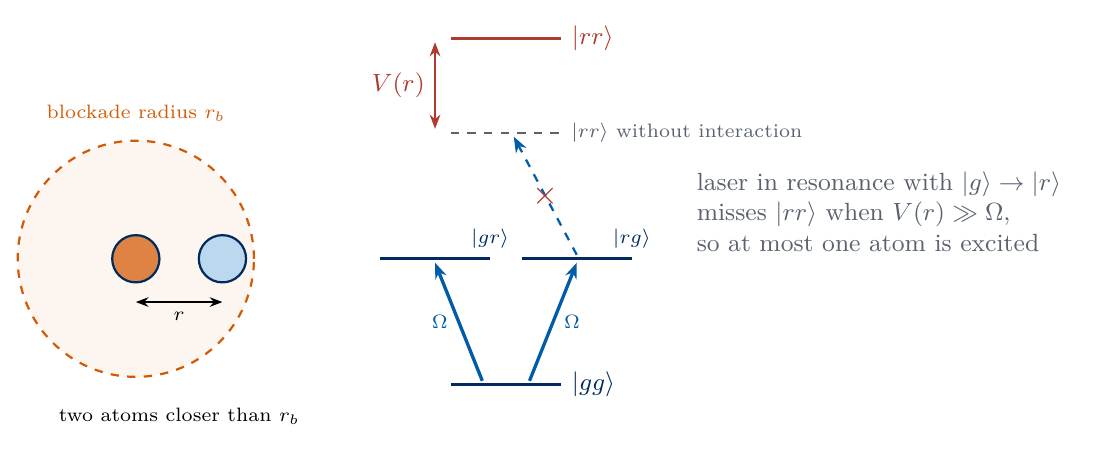

We take the $2\times4$ grid, two rows of four vertices with edges between nearest neighbours, which is the blockade graph of eight atoms in two rows. Its maximum independent sets are the two checkerboard patterns of size four. We use $B=2$, check the penalty argument on all 256 bit strings for several values of $B$, and verify the fields (23).

B = 0.5: every minimiser of (22) is an independent set: False
B = 1.0: every minimiser of (22) is an independent set: True
B = 1.5: every minimiser of (22) is an independent set: True
B = 2.0: every minimiser of (22) is an independent set: True
fields h_i: [-0.5 -1.  -1.  -0.5 -0.5 -1.  -1.  -0.5] | couplings P/4 = 0.5
independent sets: 41 of 256 (random feasibility 0.160); maximum size 4, reached by ['01011010', '10100101']
training of 4 x 16 circuits: 5.6 s
 p | expected cost | P_opt  | P(independent) | M_95
 random  |    1.000    | 0.0078 |     0.160      | 382
 1       |   -1.793    | 0.0403 |     0.689      |  73
 2       |   -2.456    | 0.1447 |     0.749      |  20
 3       |   -2.955    | 0.3374 |     0.895      |   8
 4       |   -3.134    | 0.4556 |     0.836      |   5


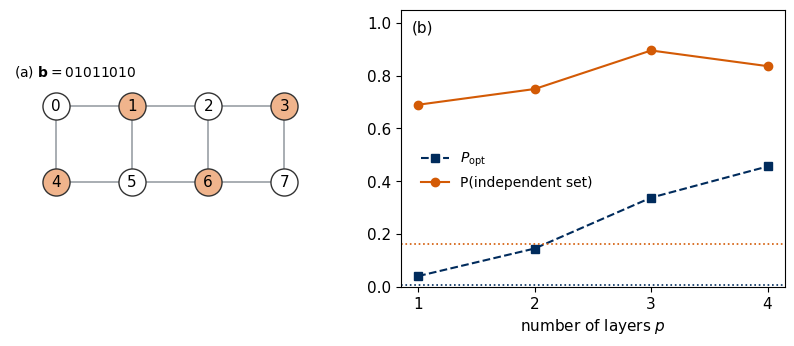

In [16]:
GRID_EDGES = [(0, 1), (1, 2), (2, 3), (4, 5), (5, 6), (6, 7), (0, 4), (1, 5), (2, 6), (3, 7)]
PEN = 2.0
size = BITS.sum(axis=1)
viol = np.array([sum(int(b[i] * b[j]) for i, j in GRID_EDGES) for b in BITS])
independent = viol == 0
for P_test in (0.5, 1.0, 1.5, 2.0):
    c_test = -size + P_test * viol
    print(f"B = {P_test}: every minimiser of (22) is an independent set: {bool(np.all(independent[c_test == c_test.min()]))}")
cost_mis = -size + PEN * viol                                          # equation (22)
Q_mis = -np.eye(n)
for i, j in GRID_EDGES:
    Q_mis[i, j] = Q_mis[j, i] = PEN / 2
assert np.allclose(np.einsum("ki,ij,kj->k", BITS, Q_mis, BITS), cost_mis)
c0_mis, h_mis, J_mis = qubo_to_ising(Q_mis)
deg = np.bincount(np.ravel(GRID_EDGES), minlength=n)
assert np.allclose(h_mis, (2 - PEN * deg) / 4)                        # equation (23)
diag_mis = c0_mis + Zsign @ h_mis + np.einsum("ki,ij,kj->k", Zsign, J_mis, Zsign)
assert np.allclose(diag_mis, cost_mis)
mis_opt = cost_mis == cost_mis.min()
mis_size = int(size[independent].max())
assert np.all(independent[mis_opt]) and np.all(size[mis_opt] == mis_size)
P_OPT_MIS_RANDOM, FEAS_RANDOM = float(mis_opt.mean()), float(independent.mean())
print("fields h_i:", h_mis, "| couplings P/4 =", PEN / 4)
print(f"independent sets: {int(independent.sum())} of 256 (random feasibility {FEAS_RANDOM:.3f}); "
      f"maximum size {mis_size}, reached by", [fmt(k) for k in np.flatnonzero(mis_opt)])
NUMBERS["MISSize"] = str(mis_size)
NUMBERS["MISFeasRandom"] = f"{FEAS_RANDOM:.3f}"
NUMBERS["MISPOptRandom"] = f"{P_OPT_MIS_RANDOM:.4f}"
DIAG_MIS = jnp.asarray(cost_mis.astype(float))

t_mis = time.perf_counter()
res_mis, states_mis = {}, {}
for p in (1, 2, 3, 4):
    th_b, probs, E_b = train_qaoa(DIAG_MIS, p, jax.random.PRNGKey(7340 + p), np.pi / 2)
    res_mis[p] = dict(E=E_b, P_opt=float(probs[mis_opt].sum()), feasible=float(probs[independent].sum()),
                      M95=M95(float(probs[mis_opt].sum())))
    states_mis[p] = probs
print(f"training of 4 x {STARTS} circuits: {time.perf_counter() - t_mis:.1f} s")
print(" p | expected cost | P_opt  | P(independent) | M_95")
print(f" random  |   {cost_mis.mean():6.3f}    | {P_OPT_MIS_RANDOM:.4f} |     {FEAS_RANDOM:.3f}      | {M95(P_OPT_MIS_RANDOM):3d}")
for p, r in res_mis.items():
    print(f" {p}       |   {r['E']:6.3f}    | {r['P_opt']:.4f} |     {r['feasible']:.3f}      | {r['M95']:3d}")
    NUMBERS[f"MISPOptP{WORDS[p]}"] = f"{r['P_opt']:.3f}"
    NUMBERS[f"MISFeasP{WORDS[p]}"] = f"{r['feasible']:.3f}"

GRID_POS = np.array([[i % 4, 1 - i // 4] for i in range(n)], dtype=float)
fig, axs = plt.subplots(1, 2, figsize=(10.0, 3.6), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axs[0]
mis_bits = BITS[np.flatnonzero(mis_opt)[0]]
for i, j in GRID_EDGES:
    ax.plot(*GRID_POS[[i, j]].T, color=COL["edge"], lw=1.2, zorder=1)
for i in range(n):
    ax.scatter(*GRID_POS[i], s=380, color=COL["g1"] if mis_bits[i] else "white", edgecolor="0.2", zorder=2)
    ax.text(*GRID_POS[i], str(i), ha="center", va="center", fontsize=11, zorder=3)
ax.set_xlim(-0.6, 3.6); ax.set_ylim(-0.7, 1.6); ax.set_aspect("equal"); ax.axis("off")
ax.text(-0.55, 1.4, f"(a) $\\mathbf{{b}}={fmt(np.flatnonzero(mis_opt)[0])}$", fontsize=10)
ps_m = np.array(sorted(res_mis))
axs[1].plot(ps_m, [res_mis[p]["P_opt"] for p in ps_m], "s--", color=COL["opt"], label=r"$P_{\rm opt}$")
axs[1].plot(ps_m, [res_mis[p]["feasible"] for p in ps_m], "o-", color=COL["qaoa"], label="P(independent set)")
axs[1].axhline(P_OPT_MIS_RANDOM, color=COL["opt"], ls=":", lw=1.2)
axs[1].axhline(FEAS_RANDOM, color=COL["qaoa"], ls=":", lw=1.2)
axs[1].set_xticks(ps_m); axs[1].set_xlabel("number of layers $p$"); axs[1].set_ylim(0, 1.05)
axs[1].legend(frameon=False, fontsize=10, loc="center left", bbox_to_anchor=(0.02, 0.42))
axs[1].text(0.03, 0.92, "(b)", transform=axs[1].transAxes)
save(fig, "fig_lab073_mis_graph"); plt.show()

Panel (a) shows the $2\times4$ grid with one maximum independent set, the four orange vertices of a checkerboard pattern. Panel (b) shows, against the number of layers, the probability $P_{\rm opt}$ of a maximum independent set (squares) and the probability that a measured bit string is an independent set at all (circles), with the random-guessing values as dotted lines. Only 41 of the 256 bit strings are independent sets, including the empty set, and only two are maximum independent sets, so random guessing rarely produces a valid answer. The trained circuits raise both probabilities by large factors, although part of their weight remains on strings that violate the constraint, because the penalty enters only as an energy. The training minimises the expected cost, which rewards large sets as well as feasibility, so the probability of an independent set need not grow at every added layer. The penalty check of the code also shows that for this graph $B=1$ already suffices, whereas $B=1/2$ makes a string with a violated edge optimal.

A measured bit string that violates the constraint is recognised classically at once and is discarded or repaired by removing one endpoint of each violated edge, which always yields an independent set. The figure below counts the outcomes of 1000 shots of the $p=4$ state.

1000 shots at p = 4: independent sets QAOA 0.814, random 0.158; maximum sets QAOA 0.449, random 0.008


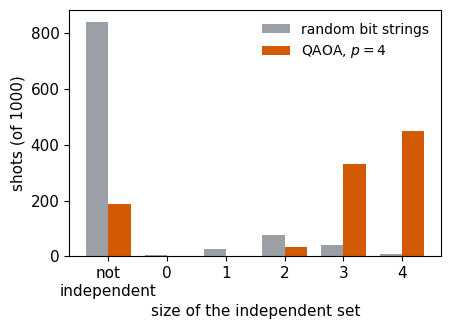

In [17]:
k1, k2 = jax.random.split(jax.random.PRNGKey(7345))
idx_m = np.asarray(sample_bits(k1, jnp.asarray(states_mis[4]), M_SHOTS))
idx_m_r = np.asarray(sample_bits(k2, uniform, M_SHOTS))

def outcome_classes(idx):
    # -1 for a string that is not an independent set, otherwise the size of the independent set
    return np.where(independent[idx], size[idx], -1)

oq, orr = outcome_classes(idx_m), outcome_classes(idx_m_r)
cats = np.arange(-1, mis_size + 1)
hq = np.array([np.sum(oq == c) for c in cats]); hr = np.array([np.sum(orr == c) for c in cats])
print(f"{M_SHOTS} shots at p = 4: independent sets QAOA {np.mean(oq >= 0):.3f}, random {np.mean(orr >= 0):.3f};"
      f" maximum sets QAOA {np.mean(oq == mis_size):.3f}, random {np.mean(orr == mis_size):.3f}")
NUMBERS["MISFracFeasQAOA"] = f"{np.mean(oq >= 0):.3f}"
NUMBERS["MISFracOptQAOA"] = f"{np.mean(oq == mis_size):.3f}"
NUMBERS["MISFracOptRandom"] = f"{np.mean(orr == mis_size):.3f}"
fig, ax = plt.subplots(figsize=(4.8, 3.2))
w = 0.38
ax.bar(cats - w / 2, hr, width=w, color=COL["rand"], label="random bit strings")
ax.bar(cats + w / 2, hq, width=w, color=COL["qaoa"], label="QAOA, $p=4$")
ax.set_xticks(cats); ax.set_xticklabels(["not\nindependent"] + [str(c) for c in cats[1:]])
ax.set_xlabel("size of the independent set"); ax.set_ylabel(f"shots (of {M_SHOTS})")
ax.legend(frameon=False, fontsize=10, loc="upper right")
save(fig, "fig_lab073_mis_samples"); plt.show()

The bars count the shots that are not independent sets (left) and the independent sets of each size, for random bit strings (grey) and for the trained $p=4$ state (orange). Random bit strings violate the constraint in most shots, whereas most QAOA shots are independent sets and the largest group are maximum independent sets of size four.

## 13. Other problems in QUBO form

Many combinatorial problems take the QUBO form after their constraints are written as penalties, as for the independent set. Ref. [8] collects Ising formulations of many NP-complete problems, and the table lists a few common ones with their binary variables and cost. In each penalty, $B$ must exceed the largest gain that a violation can bring.

| Problem | Binary variables | Cost to minimise |
|---|---|---|
| Minimum vertex cover | $x_i=1$ if vertex $i$ is in the cover | $\sum_ix_i+B\sum_{(i,j)\in E}(1-x_i)(1-x_j)$ |
| Graph colouring with $k$ colours | $x_{v,c}=1$ if vertex $v$ has colour $c$ | $B\sum_v\big(1-\sum_cx_{v,c}\big)^2+B\sum_{(u,v)\in E}\sum_cx_{u,c}x_{v,c}$ |
| Travelling salesman, $m$ cities | $x_{c,t}=1$ if city $c$ is visited at step $t$ | $\sum_{c,c'}d_{cc'}\sum_tx_{c,t}x_{c',t+1}$ plus penalties for one city per step and one step per city |
| Knapsack with an exact capacity $W$ | $x_i=1$ if item $i$ is packed | $-\sum_iv_ix_i+B\big(\sum_iw_ix_i-W\big)^2$ |
| Portfolio selection with budget $K$ | $x_i=1$ if asset $i$ is bought | $-\sum_i\mu_ix_i+q\sum_{i,j}\Sigma_{ij}x_ix_j+B\big(\sum_ix_i-K\big)^2$ |
| Sherrington–Kirkpatrick spin glass | spins $z_i=\pm1$ | $\sum_{i<j}J_{ij}z_iz_j$ with random couplings $J_{ij}$ [9] |

Here $d_{cc'}$ are distances between cities, $v_i$ and $w_i$ the values and weights of items, $\mu_i$ the expected returns of assets, $\Sigma_{ij}$ their covariance matrix and $q$ a weight of the risk. A knapsack whose capacity is an upper bound needs additional binary slack variables. Colouring and the travelling salesman need $Nk$ and $m^2$ qubits, so the encoding of the constraints sets the size of the register.

## 14. Adiabatic evolution and the Hamiltonian-variational ansatz

The QAOA circuit has the form of a Hamiltonian-variational ansatz [3], which alternates evolutions under the terms of a Hamiltonian with trainable times. For the transverse-field Ising chain, a chain of spins with $\hat Z\hat Z$ couplings in a field along $x$, this ansatz alternates $e^{-i\gamma\sum\hat Z\hat Z}$ and $e^{-i\beta\sum\hat X}$, and the QAOA has the same structure with the cost Hamiltonian in place of the chain couplings. The structure also follows from adiabatic evolution under $\hat{\mathcal H}(s)=-(1-s)\sum_i\hat X_i+s\,\hat{\mathcal H}_C$, whose ground state at $s=0$ is $|+\rangle^{\otimes N}$ and at $s=1$ the optimal bit string. If $s$ is increased slowly enough from 0 to 1, the adiabatic theorem keeps the state in the instantaneous ground state, and the evolution ends in the optimum. Dividing the evolution into $p$ steps of duration $\delta t$ at the values $s_\ell$ and splitting each step into its two groups of mutually commuting terms gives $e^{-i\delta t\hat{\mathcal H}(s_\ell)}\approx e^{+i(1-s_\ell)\delta t\sum_i\hat X_i}\,e^{-is_\ell\delta t\hat{\mathcal H}_C}$. The product is a QAOA layer (12), (13) with $\gamma_\ell=s_\ell\,\delta t$ and $\beta_\ell=-(1-s_\ell)\,\delta t$. As $p\to\infty$, the QAOA therefore contains this discretised adiabatic evolution, which reaches the optimum [1]. The trained angles of Section 9 show the same pattern at small $p$, with $\gamma_\ell$ growing and $|\beta_\ell|$ shrinking along the circuit. At small depth the trained circuit need not follow the instantaneous ground state, since its angles are optimised only for the final expected cost.

In [18]:
summary = dict(
    experiment="QAOA for MaxCut, number partitioning and maximum independent set on 8 qubits, exact state vectors and simulated shots",
    graph=dict(n=n, edges=EDGES, max_cut=cut_max, optimal_bit_strings=[fmt(k) for k in opt_idx], mean_random_cut=float(cut.mean())),
    ising=dict(c0=float(c0), coupling=0.5, fields=0.0),
    landscape_p1=dict(grid=[101, 101], min_E=float(land.min()), gamma=float(gam[ig]), beta=float(bet[ib])),
    training=dict(starts=STARTS, steps=STEPS, learning_rate=LR, per_depth={int(p): r for p, r in results.items()}),
    random_guessing=dict(P_opt=P_OPT_RANDOM, M95=M95(P_OPT_RANDOM), ratio=float(cut.mean() / cut_max)),
    sampling_p4=dict(shots=M_SHOTS, E_estimate=C_bar, E_standard_error=C_se, frac_optimal_qaoa=float(np.mean(cq == cut_max)),
                     frac_optimal_random=float(np.mean(cr == cut_max)), first_optimal_shot_qaoa=first_q, first_optimal_shot_random=first_r),
    number_partitioning=dict(numbers=A_NUM.tolist(), perfect_partitions=int(perfect.sum()), P_opt_random=P_OPT_NP_RANDOM,
                             mean_abs_residual_random=float(np.abs(resid).mean()), per_depth={int(p): r for p, r in res_np.items()},
                             shots_p4=dict(frac_perfect_qaoa=float(np.mean(rq == 0)), frac_perfect_random=float(np.mean(rr == 0)),
                                           first_perfect_qaoa=first_np, first_perfect_random=first_np_r)),
    max_independent_set=dict(edges=GRID_EDGES, penalty=PEN, mis_size=mis_size, n_independent=int(independent.sum()),
                             P_opt_random=P_OPT_MIS_RANDOM, feasible_random=FEAS_RANDOM, per_depth={int(p): r for p, r in res_mis.items()},
                             shots_p4=dict(frac_independent_qaoa=float(np.mean(oq >= 0)), frac_independent_random=float(np.mean(orr >= 0)),
                                           frac_maximum_qaoa=float(np.mean(oq == mis_size)), frac_maximum_random=float(np.mean(orr == mis_size)))),
    runtime_seconds=time.perf_counter() - started)
(RES / "lab073_results.json").write_text(json.dumps(summary, indent=2))
NUMBERS["Runtime"] = f"{summary['runtime_seconds']:.0f}"
with open(FIG / "nb_numbers_lab073.tex", "w") as f:
    for k, v in NUMBERS.items():
        f.write(f"\\newcommand{{\\labseventythree{k}}}{{{v.strip()}}}\n")
print("numbers:", NUMBERS)
print(f"runtime {summary['runtime_seconds']:.1f} s")

numbers: {'NumVertices': '8', 'NumEdges': '12', 'MaxCut': '10', 'NumOptimal': '8', 'RandomMeanCut': '6.0', 'POptRandom': '0.0312', 'MNinetyFiveRandom': '95', 'RatioPOne': '0.831', 'ExpCutPOne': '8.31', 'POptPOne': '0.322', 'MNinetyFivePOne': '8', 'RatioPTwo': '0.925', 'ExpCutPTwo': '9.25', 'POptPTwo': '0.522', 'MNinetyFivePTwo': '5', 'RatioPThree': '0.966', 'ExpCutPThree': '9.66', 'POptPThree': '0.770', 'MNinetyFivePThree': '3', 'RatioPFour': '0.983', 'ExpCutPFour': '9.83', 'POptPFour': '0.909', 'MNinetyFivePFour': '2', 'Shots': '1000', 'EstEnergyPFour': '-9.870', 'EstEnergySEPFour': '0.016', 'FracOptQAOA': '0.927', 'FracOptRandom': '0.034', 'FirstOptRandom': '26', 'NPPerfect': '44', 'NPPOptRandom': '0.172', 'NPMeanResidRandom': '3.56', 'NPPOptPOne': '0.373', 'NPResidPOne': '1.59', 'NPPOptPTwo': '0.484', 'NPResidPTwo': '1.14', 'NPPOptPThree': '0.494', 'NPResidPThree': '1.11', 'NPPOptPFour': '0.568', 'NPResidPFour': '0.91', 'NPFracPerfectQAOA': '0.548', 'NPFracPerfectRandom': '0.181', '

## 15. Exercises

1. Write the QUBO matrix of MaxCut on a triangle, list the costs of all eight bit strings, and find the maximum cut.
2. Count the perfect partitions of $2,1,2,1,2,1,2,1$ analytically, and find a list of eight positive integers with exactly two perfect partitions, a partition and its mirror image.
3. Derive equation (10) from equation (7) for a general graph, and compute $J_{ij}$ and $h_i$ for a graph with edge weights $w_{ij}$.
4. Show that the global bit flip $\prod_i\hat X_i$ commutes with $\hat{\mathcal H}_C$ of MaxCut, and explain why the optimal bit strings come in pairs.
5. Train the QAOA at $p=5$ and $p=6$ and follow the approximation ratio and $P_{\rm opt}$.
6. Evaluate the approximation ratio of the linear ramp (17) without training, for $p=1,\dots,8$ and a few values of $\delta t$, and compare it with the trained circuits.
7. Estimate the number of shots needed to resolve the gradient of $E$ with respect to $\gamma_1$ at the trained $p=2$ angles from the parameter-shift rule with shot noise.
8. Show that for the cost (22) on a single edge with $B=1/2$ the minimiser is not an independent set, and explain where the argument for $B>1$ fails.
9. Write the QUBO of the minimum vertex cover of the $2\times4$ grid, and show that the complement of a maximum independent set is a minimum vertex cover.
10. Train the QAOA for the maximum independent set with $B=1.5$ and $B=4$, and compare the probability of an independent set and of a maximum one.

## 16. Summary

A QUBO problem asks for the bit string that minimises a quadratic cost. Substituting each bit by an Ising spin turns the cost into a Hamiltonian that is diagonal in the computational basis, with every basis state a candidate solution and the ground state the optimum. A quantum algorithm for such a problem prepares a state concentrated on low-cost bit strings and reads the answer from measured bit strings, keeping the best one, whereas the variational quantum eigensolver reads an energy. The QAOA prepares this state by alternating evolution under the cost Hamiltonian with evolution under a transverse field, starting from the uniform superposition. For MaxCut on a graph with eight vertices, training its angles with automatic differentiation raises the probability of an optimal bit string from the random value $1/32$ to about $0.9$ at four layers. For number partitioning, whose couplings join every pair of numbers and whose perfect partitions are many, the same circuits raise the probability of a perfect partition by a smaller factor. A constraint such as the independence of a vertex set enters the cost as a penalty, and the infeasible samples are discarded or repaired classically. The trained angles resemble a discretised adiabatic schedule, and the expected cost needed for training is estimated from the same shots that deliver the candidates.

## References

[1] E. Farhi, J. Goldstone, and S. Gutmann, A quantum approximate optimization algorithm, [arXiv:1411.4028](https://arxiv.org/abs/1411.4028) (2014).

[2] D. P. Kingma and J. Ba, Adam: A method for stochastic optimization, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980) (2014).

[3] D. Wecker, M. B. Hastings, and M. Troyer, Progress towards practical quantum variational algorithms, Phys. Rev. A **92**, 042303 (2015), [doi:10.1103/PhysRevA.92.042303](https://doi.org/10.1103/PhysRevA.92.042303).

[4] R. M. Karp, Reducibility among combinatorial problems, in *Complexity of Computer Computations*, edited by R. E. Miller and J. W. Thatcher (Plenum, New York, 1972), pp. 85–103, [doi:10.1007/978-1-4684-2001-2_9](https://doi.org/10.1007/978-1-4684-2001-2_9).

[5] M. X. Goemans and D. P. Williamson, Improved approximation algorithms for maximum cut and satisfiability problems using semidefinite programming, J. ACM **42**, 1115 (1995), [doi:10.1145/227683.227684](https://doi.org/10.1145/227683.227684).

[6] H. Pichler, S.-T. Wang, L. Zhou, S. Choi, and M. D. Lukin, Quantum optimization for maximum independent set using Rydberg atom arrays, [arXiv:1808.10816](https://arxiv.org/abs/1808.10816) (2018).

[7] S. Ebadi, A. Keesling, M. Cain, et al., Quantum optimization of maximum independent set using Rydberg atom arrays, Science **376**, 1209 (2022), [doi:10.1126/science.abo6587](https://doi.org/10.1126/science.abo6587).

[8] A. Lucas, Ising formulations of many NP problems, Front. Phys. **2**, 5 (2014), [doi:10.3389/fphy.2014.00005](https://doi.org/10.3389/fphy.2014.00005).

[9] D. Sherrington and S. Kirkpatrick, Solvable model of a spin-glass, Phys. Rev. Lett. **35**, 1792 (1975), [doi:10.1103/PhysRevLett.35.1792](https://doi.org/10.1103/PhysRevLett.35.1792).